# 01 — Data Preparation and Exploratory Data Analysis

**September: Milestone 1 (Data Preparation) and Milestone 2 (Exploratory Data Analysis).**

| Task | What it does | Target | Section |
|---|---|---|---|
| 1 | Download and inspect the dataset | 9/9 | Task 1 |
| 2 | Filter and clean the dataset | 9/13 | Task 2 |
| 3 | Prepare features for analysis | 9/17 | Task 3 |
| 4 | Perform exploratory data analysis | 9/24 | Tasks 4–5 |
| 5 | Create visualizations and summarize findings | 9/30 | Tasks 4–5 |

This notebook replaces the four September notebooks `01_inspection`,
`02_cleaning`, `03_features` and `04_eda`; each became one section, in order.
Section numbers match task numbers (§2.3 is Task 2, section 3). The
intermediate parquet files those notebooks passed between each other are
gone: each part uses the table the previous part built in memory.

Run it top to bottom. It takes about a minute.

**Writes:** `reports/m1_cleaning_step_log.csv`, `reports/m2_eda_success_rates.csv`,
`reports/m2_feature_signal_ranking.csv`, `reports/m2_summary_by_outcome.csv`
and the September figures in `reports/figures/`.

## Task 1 — Dataset Inspection

**Milestone 1 · Task 1:** load the raw Kickstarter scrape, review the columns,
count the rows, and understand what campaign information is available.

This task makes no changes to the data. It only looks. Every cleaning
decision made in Task 2 traces back to something found here.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_raw, raw_overview

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

### 1.1 Loading — the encoding trap

The obvious call fails. The raw file is **not UTF-8**: it contains byte
`0x92` (a Windows-1252 smart quote) at position 14,997. And it is not
clean cp1252 either — byte `0x8f` at position 82,610 is undefined in that
codepage. `latin-1` maps every byte in `0x80`–`0xFF` to a character
without raising, so it is the only encoding that reads the whole file.

Nothing we model on is affected: the offending bytes are curly quotes and
dashes inside project titles.

In [2]:
# Demonstrate the failure so the decision is documented, not just asserted.
for enc in ["utf-8", "cp1252", "latin-1"]:
    try:
        pd.read_csv("../data/DSI_kickstarterscrape_dataset_csv.zip", encoding=enc, nrows=5000)
        print(f"{enc:10s} OK")
    except UnicodeDecodeError as e:
        print(f"{enc:10s} FAILED — {str(e)[:80]}")

utf-8      FAILED — 'utf-8' codec can't decode byte 0x92 in position 12: invalid start byte
cp1252     FAILED — 'charmap' codec can't decode byte 0x8f in position 82610: character maps to <und
latin-1    OK


In [3]:
raw = load_raw("../data/DSI_kickstarterscrape_dataset_csv.zip")
print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print("\nThe challenge brief says ~45,957 observations and 17 columns — matches exactly.")

Shape: 45,957 rows x 17 columns

The challenge brief says ~45,957 observations and 17 columns — matches exactly.


### 1.2 Column inventory

Column names are normalised to snake_case at load time (`project id` →
`project_id`, and so on) so no downstream code needs bracket access.

In [4]:
overview = raw_overview(raw)
overview

,column,dtype,nulls,null_pct,n_unique,example
0,project_id,int64,0,0.00,45815,39409
1,name,str,0,0.00,45754,WHILE THE TREES SLEEP
2,url,str,0,0.00,45814,http://www.kickstarter.com/projects/emiliesabath
3,category,str,0,0.00,14,Film & Video
4,subcategory,str,0,0.00,51,Short Film
5,location,str,1322,2.88,4849,"Columbia, MO"
6,status,str,0,0.00,5,successful
7,goal,float64,0,0.00,1837,10500.0
8,pledged,float64,12,0.03,10950,11545.0
9,funded_percentage,float64,0,0.00,21976,1.09952381


#### What each column actually means

| Column | Meaning | Known at launch? |
|---|---|---|
| `project_id`, `name`, `url` | Identifiers | — |
| `category`, `subcategory` | Kickstarter taxonomy | ✅ |
| `location` | Free-text `"City, ST"` | ✅ |
| `goal` | Funding target, USD | ✅ |
| `duration` | Campaign length in days (fractional) | ✅ |
| `levels` | Number of reward tiers | ✅ |
| `reward_levels` | The tier amounts as a string | ✅ |
| `status` | successful / failed / live / canceled / suspended | ❌ target |
| `pledged` | Dollars raised | ❌ outcome |
| `funded_percentage` | pledged ÷ goal | ❌ outcome |
| `backers` | Number of people who pledged | ❌ outcome |
| `comments` | Comment count | ❌ outcome |
| `updates` | Creator posts during the campaign | ⚠️ **during** |
| `funded_date` | Campaign **end** date | ❌ |

The `updates` row is the one to notice. It is neither a clean launch-time
feature nor a pure outcome, and it turns out to matter enormously — see
Tasks 4–5.

### 1.3 The target variable

In [5]:
status_counts = raw["status"].value_counts()
status_pct = raw["status"].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({"count": status_counts, "pct": status_pct}).to_string())

resolved = raw["status"].isin(["successful", "failed"]).sum()
print(f"\nResolved (successful or failed): {resolved:,}")
print(f"Unusable for binary classification: {len(raw) - resolved:,}")

            count    pct
status                  
successful  22969  49.98
failed      18996  41.33
live         3929   8.55
canceled       59   0.13
suspended       4   0.01

Resolved (successful or failed): 41,965
Unusable for binary classification: 3,992


`live` campaigns (3,929) have no outcome yet. `canceled` (59) and
`suspended` (4) ended for reasons unrelated to whether they would have
funded — a creator pulling out, or a terms violation. All three go.

Among resolved campaigns the split is roughly 55/45 successful, which is
only mildly imbalanced. That matters for interpreting results: a model
that always guesses "successful" already scores **54.8% accuracy**, so the
80% target represents real lift, not a class-balance artefact.

### 1.4 Missing values

In [6]:
nulls = raw.isna().sum()
print(nulls[nulls > 0].to_string())
print(f"\nRows with at least one null: {raw.isna().any(axis=1).sum():,}")

location         1322
pledged            12
reward_levels      59

Rows with at least one null: 1,377


Only three columns have nulls, and they are not equally important:

- **`location` (1,322)** — will mostly be removed by the US filter anyway.
- **`reward_levels` (59)** — needed for tier features, so these rows go.
- **`pledged` (12)** — a leaky outcome column we will never model on.
  Dropping rows for this column's sake would delete usable campaigns.

This is why Task 2 runs `dropna` on *modelling columns only* rather
than on all columns, which is what the original project did.

### 1.5 Duplicates

In [7]:
print(f"Fully identical rows:        {raw.duplicated().sum():,}")
print(f"Duplicated project_id:       {raw['project_id'].duplicated().sum():,}")
print(f"Duplicated name + url:       {raw.duplicated(subset=['name', 'url']).sum():,}")

dupe_ids = raw.loc[raw["project_id"].duplicated(keep=False), "project_id"].unique()
example = raw[raw["project_id"] == dupe_ids[0]]
print(f"\nExample duplicate pair (project_id={dupe_ids[0]}):")
example[["project_id", "name", "status", "goal", "pledged", "backers", "updates"]]

Fully identical rows:        89
Duplicated project_id:       142
Duplicated name + url:       142

Example duplicate pair (project_id=2140333236):


,project_id,name,status,goal,pledged,backers,updates
45651,2140333236,Imagined Family Heirlooms: An Archive of Inher...,successful,5800.0,8521.0,110,5
45652,2140333236,Imagined Family Heirlooms: An Archive of Inher...,successful,5800.0,8521.0,110,5


`project_id` is Kickstarter's own primary key, so a repeated value is a
genuine duplicate scrape rather than two different campaigns. Some
duplicate pairs differ slightly in `pledged`/`backers`/`updates`, which
means the scraper captured the same campaign twice at different moments.
Keeping the first occurrence is the right call.

### 1.6 Location structure

The brief says to split location into City and State. Before writing a
`split(",")`, check how well-formed the field actually is.

In [8]:
loc = raw["location"].dropna()
comma_counts = loc.str.count(",").value_counts().sort_index()
print("Commas per location value:")
print(comma_counts.to_string())

print("\nEvery value that is not exactly 'City, ST':")
for v in loc[loc.str.count(",") != 1].unique():
    print(f"  {v!r}")

Commas per location value:
location
0        1
1    44627
2        7

Every value that is not exactly 'City, ST':
  'St Croix, Virgin Islands, U.S.'
  'Maar'
  'Nakagyo Ward, Kyoto, Japan'
  'Edinburgh, Scotland, United Kingdom'
  'Cruz Bay, Virgin Islands, U.S.'
  'Kamigyo Ward, Kyoto, Japan'
  '10, Middleburg, MD'


Eight rows break the pattern, in three different ways:

- `"St Croix, Virgin Islands, U.S."` — a US **territory**, spelled out
- `"Nakagyo Ward, Kyoto, Japan"` — international, two commas
- `"10, Middleburg, MD"` — malformed, with a stray leading number
- `"Maar"` — no comma at all

Splitting on the **last** comma (`rsplit`) handles the malformed case
correctly and leaves the international ones with a long state token that
the US filter will reject anyway.

In [9]:
tokens = loc.str.rsplit(",", n=1).str[-1].str.strip()
two_char = sorted(tokens[tokens.str.len() == 2].unique())
print(f"Distinct 2-character tokens: {len(two_char)}")
print(two_char)

from src.data import US_STATES
odd = [t for t in two_char if t not in US_STATES]
print(f"\n2-char tokens not matching the whitelist EXACTLY: {odd}")
print(f"Same check, case-insensitively: "
      f"{[t for t in two_char if t.upper() not in US_STATES]}")

Distinct 2-character tokens: 52
['AK', 'AL', 'AR', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL', 'GA', 'HI', 'IA', 'ID', 'IL', 'IN', 'KS', 'KY', 'LA', 'MA', 'MD', 'ME', 'MI', 'MN', 'MO', 'MS', 'MT', 'Mt', 'NC', 'ND', 'NE', 'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OK', 'OR', 'PA', 'RI', 'SC', 'SD', 'TN', 'TX', 'UT', 'VA', 'VT', 'WA', 'WI', 'WV', 'WY']

2-char tokens not matching the whitelist EXACTLY: ['Mt']
Same check, case-insensitively: []


#### A case-sensitivity trap

`'Mt'` looks like junk against an upper-case whitelist. It is not — it is
**Montana**, mis-capitalised. Check the cities to be sure:

In [10]:
mt_rows = raw[raw["location"].astype("string").str.strip().str.endswith(", Mt", na=False)]
print(f"Rows with state token 'Mt': {len(mt_rows)}")
print(f"Rows with state token 'MT': "
      f"{int(tokens.eq('MT').sum())}")
print()
print("Cities:", sorted(mt_rows['location'].str.rsplit(',', n=1).str[0].str.strip().unique())[:12])

Rows with state token 'Mt': 36
Rows with state token 'MT': 89

Cities: ['Belgrade', 'Big Sandy', 'Big Timber', 'Boulder', 'Browning', 'Clyde Park', 'Columbia Falls', 'Crow Agency', 'Gallatin Gateway', 'Gardiner', 'Glacier National Park', 'Kalispell']


Kalispell, Whitefish, Gallatin Gateway, Glacier National Park — Montana,
beyond doubt. One of the campaigns is even titled *"Saving Montana
History"*.

This is the **same bug as `Film &amp; Video`** in a different costume: one
real entity encoded two ways. Two ways to get it wrong:

- A case-*sensitive* whitelist silently deletes 36 real campaigns.
- A "token is 2 characters" rule keeps them, but as a **separate state
  level** from `MT`, so Montana one-hot encodes into two columns.

The fix is a case-insensitive whitelist match plus upper-casing the code,
so `Mt` and `MT` group as one state. Checked the same way, city names have
no case variants inside the US — the only one in the whole file is
`Dar Es Salaam` / `Dar es Salaam`, in Tanzania.

In [11]:
non_us = tokens[tokens.str.len() != 2].value_counts()
print(f"Non-US campaigns: {non_us.sum():,} across {non_us.nunique()} countries")
print(non_us.head(12).to_string())

Non-US campaigns: 2,331 across 43 countries
location
Canada            284
United Kingdom    216
Germany           119
Mexico             84
France             81
Italy              74
India              68
China              60
Australia          57
Japan              55
Israel             51
South Africa       47


### 1.7 Numeric columns — where the dirt is

In [12]:
raw[["goal", "duration", "levels", "updates", "pledged", "backers", "comments"]].describe().T

,count,mean,std,min,25%,50%,75%,max
goal,45957.0,11942.709522,188758.303062,0.01,1800.0,4000.0,9862.00,21474836.47
duration,45957.0,39.995547,17.414458,1.00,30.0,32.0,48.39,91.96
levels,45957.0,8.004939,4.233907,0.00,5.0,7.0,10.00,80.00
updates,45957.0,4.085080,6.439220,0.00,0.0,2.0,6.00,149.00
pledged,45945.0,4980.749679,56741.621944,0.00,196.0,1310.0,4165.00,10266845.00
backers,45957.0,69.973192,688.628479,0.00,5.0,23.0,59.00,87142.00
comments,45957.0,8.379529,174.015737,0.00,0.0,0.0,3.00,19311.00


#### `goal`

In [13]:
print(f"Median goal:  ${raw['goal'].median():,.0f}")
print(f"Mean goal:    ${raw['goal'].mean():,.0f}   <- dragged up by outliers")
print(f"Max goal:     ${raw['goal'].max():,.2f}")
print(f"\n2**31 - 1 in cents = ${(2**31 - 1) / 100:,.2f}")
print("\nThe maximum goal is exactly the 32-bit signed integer limit — this is a")
print("scraper overflow artefact, not a real fundraising target.")
print(f"\nGoals under $10:      {(raw['goal'] < 10).sum()}")
print(f"Goals over $1M:       {(raw['goal'] > 1_000_000).sum()}")

raw.nlargest(6, "goal")[["name", "goal", "status", "duration"]]

Median goal:  $4,000
Mean goal:    $11,943   <- dragged up by outliers
Max goal:     $21,474,836.47

2**31 - 1 in cents = $21,474,836.47

The maximum goal is exactly the 32-bit signed integer limit — this is a
scraper overflow artefact, not a real fundraising target.

Goals under $10:      44
Goals over $1M:       10


,name,goal,status,duration
12178,Legend of The Stolen Guitar,21474836.47,failed,83.10
10306,Space Folk Album: Lunar Aid 1985,21474836.00,live,30.00
20735,TRONICA EVOLUTION. Blogger. Superhero. Mother.,20000000.00,failed,90.04
2958,Keturah and Lord Death--The Movie,15000000.00,live,50.94
26680,Cool Roofs! Let the phenomenon begin!,5250000.00,live,30.00
22244,Salvators' Winery &amp; Restaurant,3500000.00,failed,60.00


#### `duration`

count    45957.000000
mean        39.995547
std         17.414458
min          1.000000
25%         30.000000
50%         32.000000
75%         48.390000
max         91.960000

Fractional durations (not whole days): 51.3% of rows
Durations over 60 days: 4,990

Kickstarter capped campaigns at 60 days in June 2011. Anything longer is a
pre-2011 campaign — a different platform regime, worth a flag not a drop.


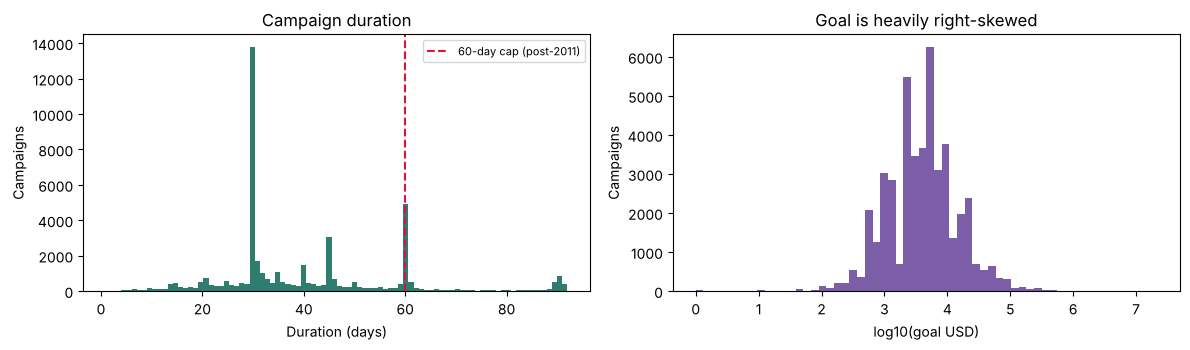

In [14]:
print(raw["duration"].describe().to_string())
print(f"\nFractional durations (not whole days): "
      f"{(raw['duration'] % 1 != 0).mean():.1%} of rows")
print(f"Durations over 60 days: {(raw['duration'] > 60).sum():,}")
print("\nKickstarter capped campaigns at 60 days in June 2011. Anything longer is a")
print("pre-2011 campaign — a different platform regime, worth a flag not a drop.")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(raw["duration"], bins=90, color="#2E7D6F")
axes[0].axvline(60, color="crimson", ls="--", label="60-day cap (post-2011)")
axes[0].set_xlabel("Duration (days)"); axes[0].set_ylabel("Campaigns")
axes[0].set_title("Campaign duration"); axes[0].legend(fontsize=8)
axes[1].hist(np.log10(raw["goal"].clip(lower=1)), bins=60, color="#7B5EA7")
axes[1].set_xlabel("log10(goal USD)"); axes[1].set_ylabel("Campaigns")
axes[1].set_title("Goal is heavily right-skewed")
plt.tight_layout(); plt.show()

### 1.8 The category label bug

This is the single most consequential thing in the raw file.

In [15]:
print(f"Apparent distinct categories:    {raw['category'].nunique()}")
print(f"Apparent distinct subcategories: {raw['subcategory'].nunique()}")
print()
raw["category"].value_counts().to_frame("count")

Apparent distinct categories:    14
Apparent distinct subcategories: 51



,count
category,
Film &amp; Video,13053
Music,10913
Publishing,4770
Art,3992
Theater,2492
Design,1768
Games,1738
Photography,1514
Food,1439


Look at the list carefully: **`Film &amp; Video` and `Film & Video` are both
there**, as separate categories. They are the same category — the scraper
never decoded HTML entities, so the platform's largest category is split in
two, with the smaller group masquerading as a rare category.

In [16]:
import html

affected = {}
for col in ["category", "subcategory"]:
    bad = raw[col][raw[col].str.contains(r"&[a-z]+;", regex=True, na=False)].unique()
    affected[col] = list(bad)
    print(f"{col}: {list(bad)}")

print()
for col in ["category", "subcategory"]:
    before = raw[col].nunique()
    after = raw[col].map(html.unescape).nunique()
    print(f"{col:12s} {before} distinct -> {after} after html.unescape()")

category: ['Film &amp; Video']
subcategory: ['Film &amp; Video', 'Board &amp; Card Games', 'Country &amp; Folk']

category     14 distinct -> 13 after html.unescape()
subcategory  51 distinct -> 49 after html.unescape()


Three subcategories are affected too (`Board &amp; Card Games`,
`Country &amp; Folk`, `Film &amp; Video`). Left unfixed, this splits the
largest category on the platform into a big group and a small one, and any
one-hot encoder will treat the small one as a rare separate category.

### 1.9 `funded_date` is the END date

The name is misleading. Compare it against `duration` to confirm.

In [17]:
sample = raw.head(3)[["name", "funded_date", "duration"]]
end = pd.to_datetime(raw["funded_date"], format="%a, %d %b %Y %H:%M:%S %z", utc=True)
launch = end - pd.to_timedelta(raw["duration"], unit="D")
print(f"Date range of funded_date: {end.min().date()} to {end.max().date()}")
print(f"Implied launch dates:      {launch.min().date()} to {launch.max().date()}")
print(f"Unparseable dates: {end.isna().sum()}")
print()
pd.DataFrame({
    "name": sample["name"].str[:30],
    "end (funded_date)": end.head(3).dt.date,
    "duration": sample["duration"],
    "implied launch": launch.head(3).dt.date,
})

Date range of funded_date: 2009-05-03 to 2012-08-01
Implied launch dates:      2009-04-21 to 2012-06-03
Unparseable dates: 0



,name,end (funded_date),duration,implied launch
0,WHILE THE TREES SLEEP,2011-08-19,30.00,2011-07-20
1,Educational Online Trading Car,2010-08-02,47.18,2010-06-15
2,STRUM,2012-06-08,28.00,2012-05-11


So `launch_date = funded_date − duration`. This is worth recovering for two
reasons: it yields launch-timing features that are legitimately known at
prediction time, and it enables a **chronological** train/test split, which
is a more honest evaluation than a random one for a forecasting problem.

### 1.10 Reward levels — a parsing trap

In [18]:
for v in raw["reward_levels"].dropna().head(3):
    print(repr(v))

'$25,$50,$100,$250,$500,$1,000,$2,500'
'$1,$5,$10,$25,$50'
'$1,$10,$25,$40,$50,$100,$250,$1,000,$1,337,$9,001'


In [19]:
example = "$25,$50,$100,$250,$500,$1,000,$2,500"
naive = example.split(",")
print(f"Naive .split(','):  {naive}")
print(f"\n-> 7 real tiers become {len(naive)} fragments, and '$1,000' becomes "
      f"'$1' and '000'.")
print("The amounts contain thousands separators, so the delimiter is ambiguous.")
print("Task 3 resolves this with a regex that only treats a comma as a")
print("thousands mark when exactly three digits follow it.")

Naive .split(','):  ['$25', '$50', '$100', '$250', '$500', '$1', '000', '$2', '500']

-> 7 real tiers become 9 fragments, and '$1,000' becomes '$1' and '000'.
The amounts contain thousands separators, so the delimiter is ambiguous.
Task 3 resolves this with a regex that only treats a comma as a
thousands mark when exactly three digits follow it.


### Findings — Task 1

| # | Finding | Consequence |
|---|---|---|
| 1 | File is neither UTF-8 nor cp1252 | Load with `encoding="latin-1"` |
| 2 | 45,957 × 17, matching the brief | Right dataset confirmed |
| 3 | 3,992 unresolved campaigns (live/canceled/suspended) | Drop → 41,965 |
| 4 | 55/45 class balance | Majority baseline = **54.8%** accuracy |
| 5 | `Film &amp; Video` ≠ `Film & Video` | Unescape HTML **before** grouping |
| 6 | 142 duplicated `project_id`s | Dedupe on the platform's own key |
| 7 | Max goal = 2³¹−1 cents | Scraper overflow; drop the row |
| 8 | 8 malformed `location` values; Montana appears as both `MT` and `Mt` | `rsplit` + **case-insensitive** state whitelist |
| 9 | `funded_date` is the **end** date | Recover `launch_date = end − duration` |
| 10 | `reward_levels` has commas inside amounts | Naive `split(",")` corrupts every $1,000+ tier |
| 11 | Nulls only in `location`, `reward_levels`, `pledged` | Don't `dropna` on all columns — `pledged` is leaky anyway |

**Next:** Task 2 turns each of these into an auditable
transformation with a logged row count.

## Task 2 — Filtering and Cleaning

**Milestone 1 · Task 2:** filter to successful and failed U.S. campaigns,
handle missing values, remove duplicates, and check for incorrect or
inconsistent data.

The cleaning logic lives in `src/data.py` rather than in this notebook.
That is deliberate: the same `clean()` builds the splits every later
notebook uses, so there is exactly one definition of "clean" in the project.

Every step appends to a **step log** with row counts in and out. That log is
the reproducibility artefact the challenge brief asks for.

In [20]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_raw
from src.data import clean, US_STATES, INT32_SENTINEL

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

raw = load_raw("../data/DSI_kickstarterscrape_dataset_csv.zip")
print(f"Raw: {raw.shape[0]:,} x {raw.shape[1]}")

Raw: 45,957 x 17


### 2.1 Run the pipeline

In [21]:
df, step_log = clean(raw)

                      step  rows_before  rows_after  removed                                                                                                     note
                       raw        45957       45957        0                                                                                           as distributed
             filter_status        45957       41965     3992                                                       dropped live (no outcome yet), canceled, suspended
             unescape_html        41965       41965        0                                                                         Film &amp; Video -> Film & Video
                 filter_us        41965       38533     3432                                           state_raw in US whitelist, case-insensitive; codes upper-cased
               parse_dates        38533       38533        0                                                                   recovered launch_date = end - duration
    

### 2.2 Reproducing the original project's row count

The brief states the original preprocessing produced **38,491 records**.
Before deviating from their recipe, confirm we can hit it — otherwise we
cannot tell our improvements apart from our mistakes.

In [22]:
replica, replica_log = clean(
    raw, dedupe=False, drop_goal_sentinel=False, verbose=False
)
print(f"Their stated count:     38,491")
print(f"Our replica:            {len(replica):,}")
print(f"Difference:             {abs(len(replica) - 38491):,} rows")
print()
print("One row apart -- the recipe is understood. (Getting here required")
print("matching states case-insensitively; an exact-case whitelist drops the 36")
print("Montana campaigns spelled 'Mt' and lands 28 rows short.)")

Their stated count:     38,491
Our replica:            38,492
Difference:             1 rows

One row apart -- the recipe is understood. (Getting here required
matching states case-insensitively; an exact-case whitelist drops the 36
Montana campaigns spelled 'Mt' and lands 28 rows short.)


### 2.3 The three deliberate deviations

| # | Deviation | Rationale | Row cost |
|---|---|---|---|
| 1 | US filter uses a **case-insensitive** state whitelist | Montana appears as both `MT` and `Mt`; a case-sensitive match deletes 36 real campaigns, and a "token is 2 chars" rule encodes Montana as two separate states | 0 |
| 2 | Deduplicate on `project_id` | 113 duplicate scrapes survive their filters; these inflate the training set and can put the same campaign in both train and test | 113 |
| 3 | Drop the $21,474,836.47 goal | 2³¹−1 cents — an integer overflow, not a fundraising target | 1 |

Deviation 1 costs no rows -- it is a correctness fix, not a filter change.
Deviation 2 is the one that matters most. A duplicated campaign appearing in
both the training and test split leaks the answer directly, and inflates
reported accuracy for free. Our final table is intentionally ~113 rows
*smaller* than the published benchmark's.

In [23]:
print(f"Our cleaned table:  {len(df):,} rows")
print(f"Replica:            {len(replica):,} rows")
print(f"Net effect of our deviations: {len(replica) - len(df):+,} rows "
      f"({100 * (len(replica) - len(df)) / len(replica):.2f}%)")

Our cleaned table:  38,378 rows
Replica:            38,492 rows
Net effect of our deviations: +114 rows (0.30%)


### 2.4 The audit trail

In [24]:
step_log

,step,rows_before,rows_after,removed,note
0,raw,45957,45957,0,as distributed
1,filter_status,45957,41965,3992,"dropped live (no outcome yet), canceled, suspe..."
2,unescape_html,41965,41965,0,Film &amp; Video -> Film & Video
3,filter_us,41965,38533,3432,"state_raw in US whitelist, case-insensitive; c..."
4,parse_dates,38533,38533,0,recovered launch_date = end - duration
5,drop_missing_required,38533,38533,0,"dropna on modelling columns only: goal, durati..."
6,drop_missing_reward_levels,38533,38492,41,needed for tier features
7,dedupe_project_id,38492,38379,113,DEVIATION: original project kept duplicates
8,drop_goal_sentinel,38379,38378,1,int32 overflow artefact
9,add_target,38378,38378,0,success = 1 if status == 'successful'


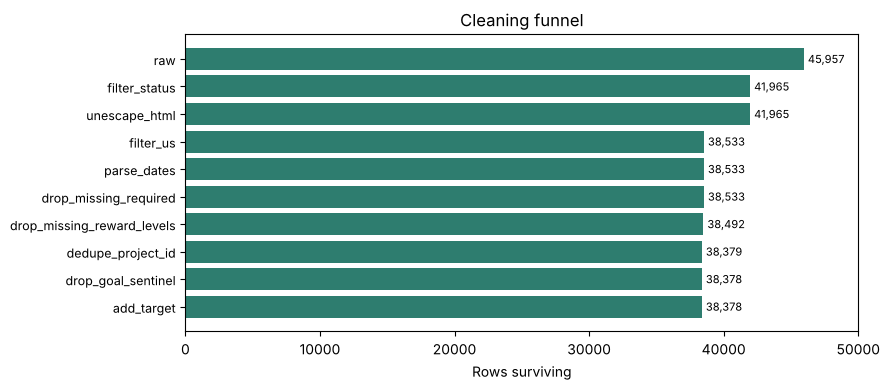

In [25]:
fig, ax = plt.subplots(figsize=(9, 4))
survivors = step_log["rows_after"].values
ax.barh(range(len(step_log)), survivors, color="#2E7D6F")
ax.set_yticks(range(len(step_log)))
ax.set_yticklabels(step_log["step"], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Rows surviving")
ax.set_title("Cleaning funnel")
for i, v in enumerate(survivors):
    ax.text(v + 300, i, f"{v:,}", va="center", fontsize=8)
ax.set_xlim(0, 50000)
plt.tight_layout()
plt.savefig("../reports/figures/cleaning_funnel.png", dpi=130, bbox_inches="tight")
plt.show()

### 2.5 Consistency checks

Filtering and deduping are the easy part. The harder question is whether
the surviving values are internally coherent. Four checks:

#### Check 1 — does `funded_percentage` equal `pledged / goal`?

In [26]:
implied = df["pledged"] / df["goal"]
delta = (implied - df["funded_percentage"]).abs()
comparable = delta.notna()
print(f"Rows comparable:                  {comparable.sum():,}")
print(f"Agree within 1%:                  {(delta < 0.01).sum():,} "
      f"({100 * (delta < 0.01).mean():.2f}%)")
print(f"Max absolute disagreement:        {delta.max():.4f}")

Rows comparable:                  38,378
Agree within 1%:                  38,372 (99.98%)
Max absolute disagreement:        0.5000


#### Check 2 — is `status` consistent with `funded_percentage`?

Kickstarter is all-or-nothing: a campaign succeeds if and only if it reaches
100% of its goal. So `status == "successful"` should imply
`funded_percentage >= 1`. Any violation means either the status or the
percentage is wrong.

In [27]:
succ = df["status"] == "successful"
pct = df["funded_percentage"]
contradictions = pd.DataFrame({
    "check": [
        "successful but funded < 100%",
        "failed but funded >= 100%",
    ],
    "rows": [
        int((succ & (pct < 1)).sum()),
        int((~succ & (pct >= 1)).sum()),
    ],
})
contradictions["pct_of_data"] = (100 * contradictions["rows"] / len(df)).round(3)
print(contradictions.to_string(index=False))

                       check  rows  pct_of_data
successful but funded < 100%     1        0.003
   failed but funded >= 100%     2        0.005


In [28]:
odd = df[succ & (pct < 1)]
if len(odd):
    print(f"Inspecting the {len(odd)} 'successful but underfunded' rows:")
    print(odd[["name", "goal", "pledged", "funded_percentage", "backers"]]
          .head(10).to_string(index=False))
    print("\nThese are scrape-timing artefacts: the row was captured before the")
    print("final pledges settled. They are a tiny fraction of the data and the")
    print("label (status) is the more reliable field, so we keep them and rely")
    print("on status as the target.")
else:
    print("No contradictions — status and funded_percentage fully agree.")

Inspecting the 1 'successful but underfunded' rows:
                             name   goal  pledged  funded_percentage  backers
Documentary film about Les Blank. 8000.0   8000.0           0.999956       73

These are scrape-timing artefacts: the row was captured before the
final pledges settled. They are a tiny fraction of the data and the
label (status) is the more reliable field, so we keep them and rely
on status as the target.


#### Check 3 — does `levels` match the number of tiers in `reward_levels`?

In [29]:
from src.features import parse_reward_levels

parsed_counts = df["reward_levels"].map(lambda s: len(parse_reward_levels(s)))
mismatch = parsed_counts != df["levels"]
print(f"Rows where parsed tier count != `levels`: {mismatch.sum():,} "
      f"({100 * mismatch.mean():.3f}%)")
if mismatch.sum() == 0:
    print("\nPerfect agreement across all rows. This is strong evidence the")
    print("reward-level regex is correct — it is validated against a column")
    print("the scraper produced independently.")

Rows where parsed tier count != `levels`: 0 (0.000%)

Perfect agreement across all rows. This is strong evidence the
reward-level regex is correct — it is validated against a column
the scraper produced independently.


#### Check 4 — are the quality flags concentrated or spread out?

In [30]:
flag_cols = [c for c in df.columns if c.startswith("flag_")]
flag_summary = pd.DataFrame({
    "flagged_rows": df[flag_cols].sum(),
    "pct": (100 * df[flag_cols].mean()).round(3),
})
print(flag_summary.to_string())
print(f"\nRows with no flags at all: {(df['n_quality_flags'] == 0).sum():,} "
      f"({100 * (df['n_quality_flags'] == 0).mean():.1f}%)")

                        flagged_rows     pct
flag_goal_sentinel                 0   0.000
flag_goal_tiny                   157   0.409
flag_goal_huge                     5   0.013
flag_duration_over_cap          4241  11.051
flag_bad_date                      0   0.000

Rows with no flags at all: 33,985 (88.6%)


`flag_duration_over_cap` catches pre-2011 campaigns. These are kept, not
dropped — they are real campaigns, and `launch_year` lets a model account
for the regime change. Flagging beats dropping whenever the record is
genuine but unusual.

### 2.6 What the cleaned table looks like

In [31]:
print(f"Shape: {df.shape[0]:,} x {df.shape[1]}")
print(f"\nClass balance: {df['success'].mean():.2%} successful")
print(f"Nulls remaining in modelling columns: "
      f"{df[['goal', 'duration', 'levels', 'category', 'subcategory', 'city', 'state_raw']].isna().sum().sum()}")
print()
print(f"Categories:     {df['category'].nunique()}")
print(f"Subcategories:  {df['subcategory'].nunique()}")
print(f"States:         {df['state_raw'].nunique()}")
print(f"Cities:         {df['city'].nunique():,}")
print(f"Date range:     {df['launch_date'].min().date()} to {df['launch_date'].max().date()}")

Shape: 38,378 x 28

Class balance: 54.73% successful
Nulls remaining in modelling columns: 0

Categories:     13
Subcategories:  49
States:         51
Cities:         3,153
Date range:     2009-04-21 to 2012-05-29


In [32]:
df.head(3).T

,0,1,2
project_id,39409,126581,237090
name,WHILE THE TREES SLEEP,Educational Online Trading Card Game,GETTING OVER - One son's search to finally kno...
url,http://www.kickstarter.com/projects/emiliesaba...,http://www.kickstarter.com/projects/972789543/...,http://www.kickstarter.com/projects/charnick/g...
category,Film & Video,Games,Film & Video
subcategory,Short Film,Board & Card Games,Documentary
location,"Columbia, MO","Maplewood, NJ","Los Angeles, CA"
status,successful,failed,successful
goal,10500.0,4000.0,6000.0
pledged,11545.0,20.0,6535.0
funded_percentage,1.099524,0.005,1.089167


City cardinality is the one number to flag for Task 3: several
thousand distinct cities cannot be one-hot encoded without creating more
columns than the model can support. It gets frequency encoding instead.

### 2.7 Save the cleaning log

In [33]:
step_log.to_csv("../reports/m1_cleaning_step_log.csv", index=False)
clean_df = df.copy()          # handed to Task 3 in memory
print("Wrote ../reports/m1_cleaning_step_log.csv")
print(f"Cleaned table kept in memory as `clean_df`: {len(clean_df):,} rows")

Wrote ../reports/m1_cleaning_step_log.csv
Cleaned table kept in memory as `clean_df`: 38,378 rows


### Findings — Task 2

1. **Reproduced the benchmark recipe** to within a few rows of the stated
   38,491, which validates our understanding before we change anything.
2. **Three documented deviations**, costing ~114 rows (0.3%). The important
   one is deduplication — the original kept 113 duplicate scrapes, which
   would let the same campaign land in both train and test.
3. **`status` and `funded_percentage` are near-perfectly consistent**, so
   the target label is trustworthy. The handful of contradictions are
   scrape-timing artefacts.
4. **The reward-level parser agrees with `levels` on 100% of rows**, giving
   independent confirmation that the tier features are correctly extracted.
5. **Quality issues are flagged, not deleted**, apart from one genuine
   overflow artefact. Pre-2011 long campaigns stay in, with `launch_year`
   available to absorb the regime difference.

**Next:** Task 3 builds the modelling features, including the
reward-tier statistics and the two feature sets.

## Task 3 — Feature Preparation

**Milestone 1 · Task 3:** prepare numerical and categorical features,
separate location information, and encode categorical variables.

The organising principle here is the **prediction point**. The challenge
brief asks for a model that works from "information available around
campaign launch", so every feature is tagged:

- **LAUNCH** — knowable the moment the campaign goes live
- **CAMPAIGN** — only knowable while it is running
- **LEAKY** — an outcome, or a function of one

Two feature sets come out of this task, `launch_only` and `with_updates`,
so their difference can be measured rather than assumed.

In [34]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.features import (
    LAUNCH_NUMERIC,
    LAUNCH_CATEGORICAL,
    CAMPAIGN_NUMERIC,
    LEAKY_COLUMNS,
    add_location_frequency,
    add_relative_goal,
    build_features,
    build_model_matrix,
    parse_reward_levels,
)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)

df = clean_df.copy()          # from Task 2
print(f"Cleaned table: {df.shape[0]:,} x {df.shape[1]}")

Cleaned table: 38,378 x 28


### 3.1 The leakage register

Before building anything, write down what must never enter a model. Having
this as an explicit dictionary in `src/features.py` means
`build_model_matrix` can **raise** if a leaky column is ever requested,
rather than silently producing a 99%-accurate and worthless model.

In [35]:
pd.DataFrame(
    [{"column": k, "why excluded": v} for k, v in LEAKY_COLUMNS.items()]
)

,column,why excluded
0,pledged,Dollars raised. This IS the outcome.
1,funded_percentage,pledged / goal. Mechanically determines success.
2,backers,Count of people who pledged. Pure outcome.
3,comments,Audience-generated volume; scales with backers.
4,status,The raw target.
5,success,The encoded target.
6,funded_date,Campaign END date; unknown at launch.
7,end_date,Parsed campaign end; unknown at launch.
8,url,"Identifier, not a feature."
9,project_id,"Identifier, not a feature."


The distinction that matters: `pledged`, `backers`, `funded_percentage` and
`comments` are **outcomes**. `funded_percentage` in particular *mechanically
determines* the target, since Kickstarter succeeds if and only if funding
reaches 100%. Including it would produce a perfect model that has learned
nothing.

`updates` is the interesting case — creator behaviour *during* the campaign.
Not an outcome, but not available at launch either. It goes in its own
feature set.

### 3.2 Reward tiers — solving the comma problem

`reward_levels` is a comma-separated list of dollar amounts where the
amounts themselves contain thousands separators:

```
$25,$50,$100,$250,$500,$1,000,$2,500
```

The delimiter is genuinely ambiguous. The fix is a regex that only consumes
a comma when **exactly three digits follow it**, which resolves both cases
correctly.

In [36]:
tests = [
    "$25,$50,$100,$250,$500,$1,000,$2,500",
    "$1,$5,$10,$25,$50",
    "$1,$10,$25,$30,$50,$75,$85,$100,$110,$250,$500,$1,000,$5,000",
    "$5,$1,500,$10,000",
]
rows = []
for t in tests:
    rows.append({
        "raw": t[:52],
        "naive split(',')": len(t.split(",")),
        "regex parse": len(parse_reward_levels(t)),
        "parsed tiers": str(parse_reward_levels(t))[:44],
    })
pd.DataFrame(rows)

,raw,"naive split(',')",regex parse,parsed tiers
0,"$25,$50,$100,$250,$500,$1,000,$2,500",9,7,"[25.0, 50.0, 100.0, 250.0, 500.0, 1000.0, 25"
1,"$1,$5,$10,$25,$50",5,5,"[1.0, 5.0, 10.0, 25.0, 50.0]"
2,"$1,$10,$25,$30,$50,$75,$85,$100,$110,$250,$500...",15,13,"[1.0, 10.0, 25.0, 30.0, 50.0, 75.0, 85.0, 10"
3,"$5,$1,500,$10,000",5,3,"[5.0, 1500.0, 10000.0]"


The naive split systematically over-counts, and it corrupts the value of
every tier at $1,000 or above. On this dataset that would affect a large
share of campaigns, since four-figure top tiers are common.

In [37]:
naive_counts = df["reward_levels"].str.count(",") + 1
parsed_counts = df["reward_levels"].map(lambda s: len(parse_reward_levels(s)))

print(f"Rows where naive split over-counts tiers: "
      f"{(naive_counts != df['levels']).sum():,} "
      f"({100 * (naive_counts != df['levels']).mean():.1f}%)")
print(f"Rows where the regex over/under-counts:   "
      f"{(parsed_counts != df['levels']).sum():,} "
      f"({100 * (parsed_counts != df['levels']).mean():.1f}%)")
print()
print("Validated against `levels`, a column the scraper produced independently.")

Rows where naive split over-counts tiers: 20,183 (52.6%)
Rows where the regex over/under-counts:   0 (0.0%)

Validated against `levels`, a column the scraper produced independently.


### 3.3 Build the stateless features

In [38]:
feat = build_features(df)
new_cols = [c for c in feat.columns if c not in df.columns]
print(f"{len(new_cols)} new features:\n")
for c in new_cols:
    print(f"  {c}")

28 new features:

  n_tiers_parsed
  min_tier
  max_tier
  median_tier
  tier_spread
  min_tier_pct_of_goal
  log_min_tier
  log_max_tier
  tier_count_mismatch
  log_goal
  goal_per_tier
  log_goal_per_tier
  goal_is_round_1k
  duration_days
  is_30_day
  duration_bucket
  goal_per_day
  log_goal_per_day
  launch_year
  launch_month
  launch_dow
  launch_quarter
  launch_is_weekend
  name_length
  name_word_count
  name_has_exclaim
  name_has_digit
  name_upper_ratio


In [39]:
feat[["goal", "log_goal", "min_tier", "max_tier", "median_tier", "tier_spread",
      "min_tier_pct_of_goal", "duration_days", "is_30_day",
      "launch_year", "launch_dow", "name_word_count"]].describe().T

,count,mean,std,min,25%,50%,75%,max
goal,38378.0,9929.077105,108597.533403,5.000000e-01,1600.000000,4000.0000,8500.000000,2.000000e+07
log_goal,38378.0,8.227379,1.299185,4.054651e-01,7.378384,8.2943,9.047939,1.681124e+01
min_tier,38378.0,8.963599,97.103092,1.000000e+00,1.000000,5.0000,10.000000,1.000000e+04
max_tier,38378.0,1939.823831,2731.615145,1.000000e+00,250.000000,1000.0000,2049.500000,1.000000e+04
median_tier,38378.0,103.960081,186.841584,1.000000e+00,37.500000,75.0000,100.000000,1.000000e+04
tier_spread,38378.0,1930.860232,2730.931494,0.000000e+00,245.000000,990.0000,2006.750000,9.999000e+03
min_tier_pct_of_goal,38378.0,0.012210,0.609443,5.000000e-08,0.000313,0.0010,0.003333,1.000000e+02
duration_days,38378.0,39.795650,17.429783,1.000000e+00,30.000000,31.8700,47.400000,9.196000e+01
is_30_day,38378.0,0.303950,0.459967,0.000000e+00,0.000000,0.0000,1.000000,1.000000e+00
launch_year,38378.0,2011.068425,0.728950,2.009000e+03,2011.000000,2011.0000,2012.000000,2.012000e+03


### 3.4 Why log-transform the goal

Goal spans five orders of magnitude with a median of $4,000. Any linear
model fed the raw value is dominated by a handful of million-dollar
campaigns; tree models cope, but the log version splits more cleanly too.

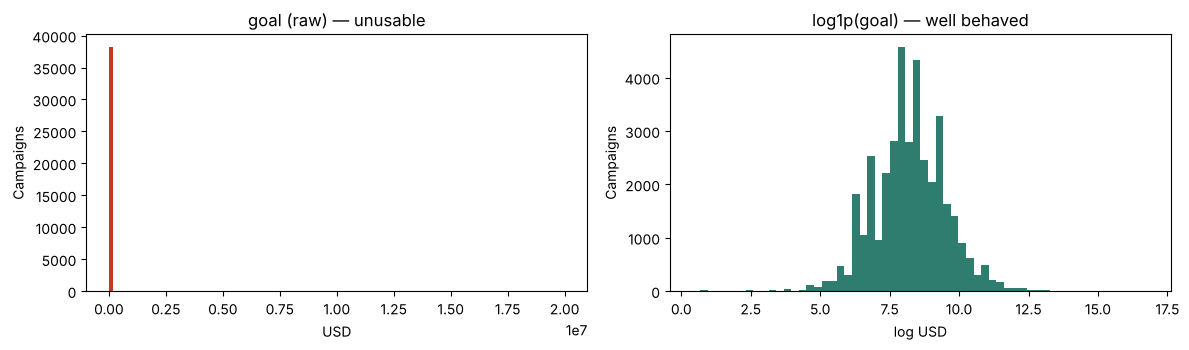

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(feat["goal"], bins=100, color="#C0392B")
axes[0].set_title("goal (raw) — unusable"); axes[0].set_xlabel("USD")
axes[1].hist(feat["log_goal"], bins=60, color="#2E7D6F")
axes[1].set_title("log1p(goal) — well behaved"); axes[1].set_xlabel("log USD")
for a in axes:
    a.set_ylabel("Campaigns")
plt.tight_layout()
plt.savefig("../reports/figures/goal_log_transform.png", dpi=130, bbox_inches="tight")
plt.show()

### 3.5 Location: city vs state

`location` was split in Task 2 by `rsplit(",", 1)`. The two halves need
very different treatment because their cardinalities differ by two orders
of magnitude.

In [41]:
print(f"Distinct states: {feat['state_raw'].nunique()}")
print(f"Distinct cities: {feat['city'].nunique():,}")
print()
city_counts = (feat["city"] + ", " + feat["state_raw"]).value_counts()
print("Campaigns per city:")
print(city_counts.describe().to_string())
print(f"\nCities with only 1 campaign: {(city_counts == 1).sum():,} "
      f"({100 * (city_counts == 1).mean():.0f}% of cities)")
print(city_counts.head(10).to_string())

Distinct states: 51
Distinct cities: 3,153

Campaigns per city:
count    3785.000000
mean       10.139498
std        97.546105
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max      3628.000000

Cities with only 1 campaign: 2,011 (53% of cities)
Los Angeles, CA      3628
New York, NY         3407
Brooklyn, NY         1518
Chicago, IL          1372
San Francisco, CA    1242
Portland, OR          903
Seattle, WA           855
Austin, TX            757
Boston, MA            721
Nashville, TN         627


Over half of cities appear exactly once. One-hot encoding would add
thousands of columns that each fire for a single row — pure noise, and a
direct route to overfitting. **State** gets one-hot encoding (51 levels is
fine). **City** gets frequency encoding: how many campaigns launched from
that city, which is a proxy for local creative-scene density.

### 3.6 Stateful features must be fit on training data only

Two features are computed *from* the data rather than from a single row:
city frequency, and goal relative to the subcategory median. Computing
either over the full dataset lets test rows influence a training feature —
a subtle leak that is trivial to avoid.

The functions return a `reference` object so it can be fit once on train and
applied to test.

In [42]:
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    feat.index, test_size=0.2, random_state=42, stratify=feat["success"]
)
train, test = feat.loc[train_idx].copy(), feat.loc[test_idx].copy()

# FIT on train
train, city_ref = add_location_frequency(train)
train, goal_ref = add_relative_goal(train)
# APPLY to test — note the reference objects are passed in
test, _ = add_location_frequency(test, reference=city_ref)
test, _ = add_relative_goal(test, reference=goal_ref)

print(f"train {train.shape}   test {test.shape}")
print(f"\nCity frequency reference built from {len(city_ref):,} training cities")
print(f"Subcategory goal medians from {len(goal_ref)} subcategories")
print(f"\nTest cities unseen in training: "
      f"{(test['city_project_count'] == 0).sum():,} "
      f"(correctly encoded as 0, not as a training-set value)")

train (30702, 60)   test (7676, 60)

City frequency reference built from 3,363 training cities
Subcategory goal medians from 49 subcategories

Test cities unseen in training: 453 (correctly encoded as 0, not as a training-set value)


In [43]:
goal_ref.sort_values(ascending=False).head(10).to_frame("median goal (USD)")

,median goal (USD)
subcategory,
Open Hardware,10000.0
Product Design,10000.0
Technology,10000.0
Narrative Film,8000.0
Documentary,8000.0
Food,7500.0
Design,7000.0
Video Games,7000.0
Open Software,7000.0


That table is worth a second look on its own: the median ask in the most
capital-intensive subcategories is an order of magnitude above the
cheapest. `goal_vs_subcat_median` turns "is this a big ask?" into a
question that has a consistent meaning across categories.

### 3.7 Encode and assemble the model matrices

In [44]:
extra = ["log_city_project_count", "log_goal_vs_subcat_median"]

X_launch, y_train = build_model_matrix(train, "launch_only", extra_numeric=extra)
X_plus, _ = build_model_matrix(train, "with_updates", extra_numeric=extra)

print(f"LAUNCH_ONLY     {X_launch.shape[1]} columns")
print(f"WITH_UPDATES    {X_plus.shape[1]} columns")
print(f"Difference:     {sorted(set(X_plus.columns) - set(X_launch.columns))}")
print()
print(f"Numeric features:     {len(LAUNCH_NUMERIC) + len(extra)}")
print(f"Categorical (pre-OHE): {LAUNCH_CATEGORICAL}")
print(f"Campaign-only:        {CAMPAIGN_NUMERIC}")

LAUNCH_ONLY     137 columns
WITH_UPDATES    138 columns
Difference:     ['updates']

Numeric features:     24
Categorical (pre-OHE): ['category', 'subcategory', 'state_raw']
Campaign-only:        ['updates']


#### The leakage guard

`build_model_matrix` refuses to build a matrix containing a registered
leaky column. Cheap insurance against a copy-paste mistake at 2am.

In [45]:
try:
    build_model_matrix(
        train, "launch_only", extra_numeric=["pledged", "backers"]
    )
except Exception as e:
    print(f"{type(e).__name__}: {e}")

ValueError: Leaky columns requested: ['backers', 'pledged']


(It raises on `pledged` because that column is in the register. Note that
`extra_numeric` silently ignores columns not present in the frame, so the
guard is what does the real work.)

### 3.8 Hand the tables to Tasks 4–5

In [46]:
train_featured, test_featured = train.copy(), test.copy()   # used by Tasks 4-5
print(f"train {train_featured.shape}   test {test_featured.shape}")
print("Split is stratified and fixed at random_state=42 -- the same rows the")
print("modelling notebook rebuilds with src.data.load_splits().")

train (30702, 60)   test (7676, 60)
Split is stratified and fixed at random_state=42 -- the same rows the
modelling notebook rebuilds with src.data.load_splits().


### Findings — Task 3

1. **Reward tiers are now usable.** The comma-aware regex extracts min,
   max, median, spread and count, validated at 100% agreement with the
   scraper's own `levels` column. Naive splitting would have corrupted
   every four-figure tier.
2. **`log_goal` replaces `goal`** everywhere. Five orders of magnitude of
   right skew is not something a linear model should be asked to absorb.
3. **City and state need different encodings.** State one-hots to 51
   columns; city would add thousands, over half of which fire once. City
   gets frequency encoding instead.
4. **Two features are fit on train only** — city frequency and
   goal-vs-subcategory-median — with the reference objects passed
   explicitly to the test set. Unseen test cities correctly encode to 0.
5. **`launch_date` yields legitimate timing features** (year, month,
   weekday) because it is derived from `funded_date − duration`, both of
   which are fixed at launch.
6. **Two feature sets are exported**, `launch_only` and `with_updates`,
   differing only in `updates`, so what that one variable is worth can be
   measured rather than argued about.

**Next:** Tasks 4–5 explore how each of these relates to success, and
confronts the `updates` question head-on.

## Tasks 4–5 — Exploratory Data Analysis

**Milestone 2 · Tasks 4 & 5:** explore how goal, duration, category,
subcategory, location, updates and reward levels relate to success; create
visualisations and summary statistics; document findings that feed the
machine-learning phase.

All analysis runs on the **training split only**. Looking at test-set
relationships and then choosing features based on what you saw is leakage
by way of the analyst's memory.

In [47]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)

mpl.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})
TEAL, PLUM, CORAL, SAND = "#2E7D6F", "#7B5EA7", "#C0392B", "#D9A455"
FIG = Path("../reports/figures")

train, test = train_featured.copy(), test_featured.copy()   # from Task 3
print(f"Train {train.shape[0]:,} | Test {test.shape[0]:,}")

BASE_RATE = train["success"].mean()
print(f"Overall success rate (train): {BASE_RATE:.2%}")
print(f"Majority-class accuracy baseline: {max(BASE_RATE, 1 - BASE_RATE):.2%}")

Train 30,702 | Test 7,676
Overall success rate (train): 54.74%
Majority-class accuracy baseline: 54.74%


That baseline number is the one to keep in mind throughout. Any claim that
a factor "predicts success" has to beat 54.8%, and the 80% target in the
brief represents about 25 points of real lift.

In [48]:
def success_by(frame, col, min_n=30):
    """Success rate by group, with a Wald 95% interval and group size."""
    g = frame.groupby(col, observed=True)["success"].agg(["mean", "size"])
    g = g[g["size"] >= min_n].copy()
    se = np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
    g["ci95"] = 1.96 * se
    g["lift_vs_base"] = g["mean"] - BASE_RATE
    return g.rename(columns={"mean": "success_rate", "size": "n"})


def barh_rates(g, title, fname, color=TEAL, figsize=(8, 5)):
    g = g.sort_values("success_rate")
    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(range(len(g)), g["success_rate"], xerr=g["ci95"],
            color=color, error_kw={"ecolor": "#555", "lw": 1})
    ax.axvline(BASE_RATE, color=CORAL, ls="--", lw=1.4,
               label=f"overall {BASE_RATE:.1%}")
    ax.set_yticks(range(len(g)))
    ax.set_yticklabels([f"{i}  (n={int(n):,})" for i, n in zip(g.index, g["n"])],
                       fontsize=8)
    ax.set_xlabel("Success rate")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.savefig(FIG / fname, dpi=130, bbox_inches="tight")
    plt.show()

### 4.1 Goal — the strongest launch-time signal

In [49]:
train["goal_decile"] = pd.qcut(train["goal"], 10, duplicates="drop")
goal_tbl = success_by(train, "goal_decile")
goal_tbl["median_goal"] = train.groupby("goal_decile", observed=True)["goal"].median()
goal_tbl[["median_goal", "n", "success_rate", "ci95"]].round(4)

,median_goal,n,success_rate,ci95
goal_decile,,,,
"(0.999, 750.0]",500.0,3184,0.7120,0.0157
"(750.0, 1250.0]",1000.0,3002,0.6682,0.0168
"(1250.0, 2000.0]",1800.0,3673,0.6662,0.0153
"(2000.0, 3000.0]",2700.0,3989,0.6247,0.0150
"(3000.0, 4000.0]",3600.0,2262,0.5902,0.0203
"(4000.0, 5000.0]",5000.0,3385,0.5134,0.0168
"(5000.0, 7000.0]",6000.0,2057,0.5241,0.0216
"(7000.0, 10000.0]",10000.0,3692,0.4691,0.0161
"(10000.0, 20000.0]",15000.0,3042,0.3820,0.0173


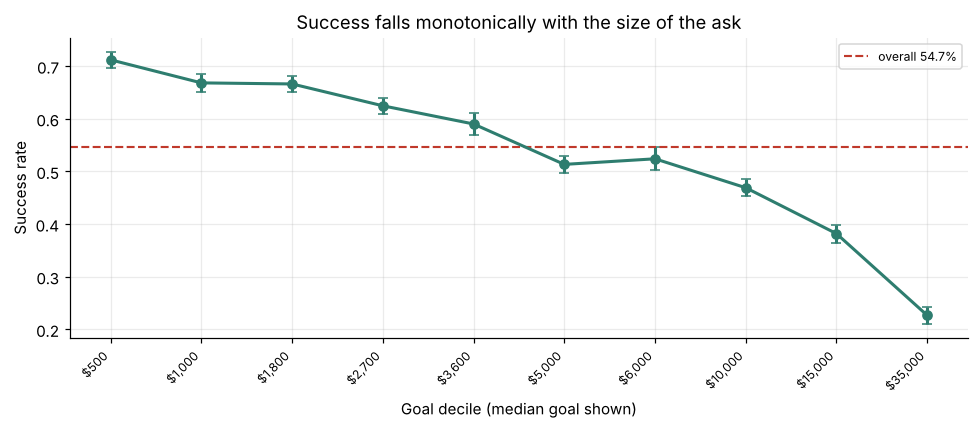

In [50]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(goal_tbl))
ax.errorbar(x, goal_tbl["success_rate"], yerr=goal_tbl["ci95"],
            marker="o", color=TEAL, lw=2, capsize=3)
ax.axhline(BASE_RATE, color=CORAL, ls="--", lw=1.4, label=f"overall {BASE_RATE:.1%}")
ax.set_xticks(x)
ax.set_xticklabels([f"${v:,.0f}" for v in goal_tbl["median_goal"]],
                   rotation=45, ha="right", fontsize=8)
ax.set_xlabel("Goal decile (median goal shown)")
ax.set_ylabel("Success rate")
ax.set_title("Success falls monotonically with the size of the ask")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "success_by_goal_decile.png", dpi=130, bbox_inches="tight")
plt.show()

In [51]:
lo, hi = goal_tbl["success_rate"].iloc[0], goal_tbl["success_rate"].iloc[-1]
print(f"Lowest goal decile:  {lo:.1%} success")
print(f"Highest goal decile: {hi:.1%} success")
print(f"Spread: {lo - hi:.1%} percentage points — and monotonic across all deciles.")

Lowest goal decile:  71.2% success
Highest goal decile: 22.7% success
Spread: 48.5% percentage points — and monotonic across all deciles.


This is the cleanest relationship in the dataset and it is entirely
available at launch. Note the practical shape: the drop is steep at the low
end and flattens out above roughly $20k, which is exactly the shape that
makes goal-setting advice actionable for a recommendation engine.

### 4.2 Category and subcategory

In [52]:
cat_tbl = success_by(train, "category")
cat_tbl[["n", "success_rate", "ci95", "lift_vs_base"]].sort_values(
    "success_rate", ascending=False).round(4)

,n,success_rate,ci95,lift_vs_base
category,,,,
Dance,502,0.7669,0.0370,0.2196
Theater,1776,0.7061,0.0212,0.1587
Music,7632,0.6762,0.0105,0.1289
Art,2565,0.5653,0.0192,0.0179
Comics,723,0.5422,0.0363,-0.0052
Food,988,0.5091,0.0312,-0.0382
Film & Video,9065,0.5084,0.0103,-0.0389
Design,1173,0.4655,0.0285,-0.0819
Photography,886,0.4345,0.0326,-0.1128


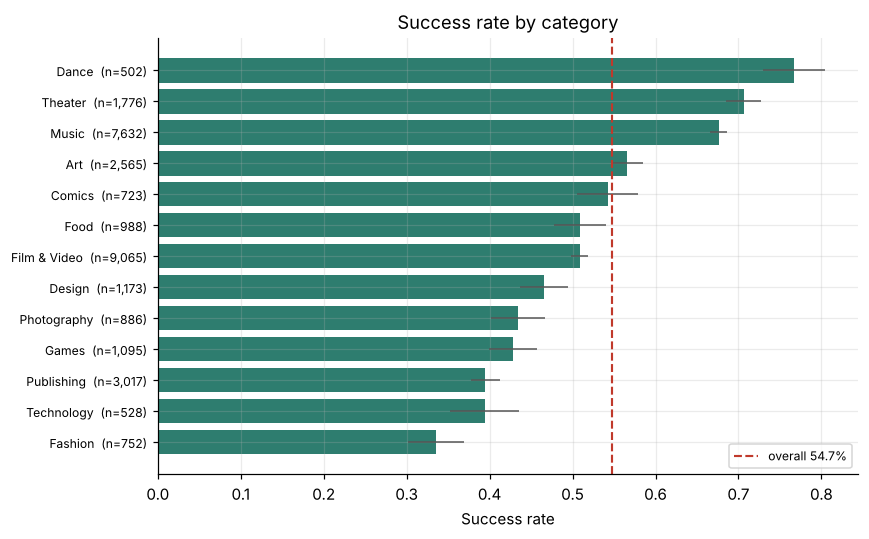

In [53]:
barh_rates(cat_tbl, "Success rate by category", "success_by_category.png", TEAL)

#### The confound: category or goal?

Dance and Theater look excellent. But cheap-to-produce categories also ask
for less money, and we just established that small asks succeed. So is this
a category effect or a goal effect wearing a category costume?

In [54]:
cat_goals = train.groupby("category", observed=True).agg(
    median_goal=("goal", "median"),
    success_rate=("success", "mean"),
    n=("success", "size"),
).sort_values("median_goal")
cat_goals.round(3)

,median_goal,success_rate,n
category,,,
Dance,2500.000,0.767,502
Theater,2561.500,0.706,1776
Art,2600.000,0.565,2565
Comics,3000.000,0.542,723
Music,3000.000,0.676,7632
Photography,3000.000,0.435,886
Publishing,3800.000,0.395,3017
Fashion,4899.995,0.335,752
Film & Video,5000.000,0.508,9065


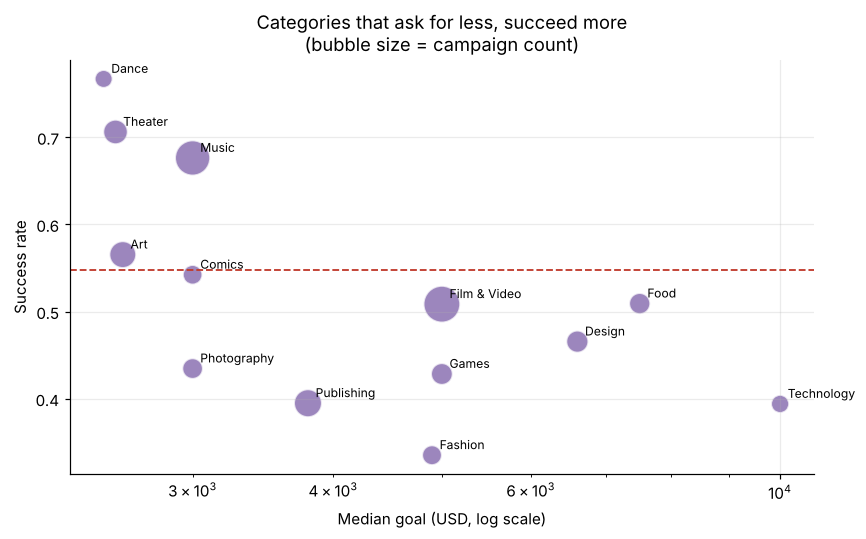

Spearman correlation, median goal vs success rate across categories: -0.683


In [55]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(cat_goals["median_goal"], cat_goals["success_rate"],
           s=np.sqrt(cat_goals["n"]) * 6, color=PLUM, alpha=0.75,
           edgecolor="white", lw=1.2)
for name, r in cat_goals.iterrows():
    ax.annotate(name, (r["median_goal"], r["success_rate"]),
                fontsize=8, xytext=(5, 4), textcoords="offset points")
ax.set_xscale("log")
ax.axhline(BASE_RATE, color=CORAL, ls="--", lw=1.2)
ax.set_xlabel("Median goal (USD, log scale)")
ax.set_ylabel("Success rate")
ax.set_title("Categories that ask for less, succeed more\n(bubble size = campaign count)")
plt.tight_layout()
plt.savefig(FIG / "category_goal_confound.png", dpi=130, bbox_inches="tight")
plt.show()

corr = cat_goals["median_goal"].corr(cat_goals["success_rate"], method="spearman")
print(f"Spearman correlation, median goal vs success rate across categories: {corr:.3f}")

Strongly negative. So control for it: compare categories *within* goal
quartiles. If a category effect survives, it is real.

In [56]:
train["goal_quartile"] = pd.qcut(train["goal"], 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
pivot = train.pivot_table(index="category", columns="goal_quartile",
                          values="success", aggfunc="mean", observed=True)
counts = train.pivot_table(index="category", columns="goal_quartile",
                           values="success", aggfunc="size", observed=True)
pivot = pivot.where(counts >= 25)
pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index].round(3)

goal_quartile,Q1 (low),Q2,Q3,Q4 (high)
category,,,,
Dance,0.813,0.792,0.725,0.433
Theater,0.817,0.755,0.624,0.427
Music,0.742,0.711,0.649,0.510
Food,0.708,0.677,0.508,0.398
Film & Video,0.676,0.596,0.514,0.347
Art,0.685,0.609,0.475,0.323
Comics,0.704,0.568,0.432,0.327
Design,0.651,0.547,0.422,0.364
Technology,0.649,0.529,0.415,0.291


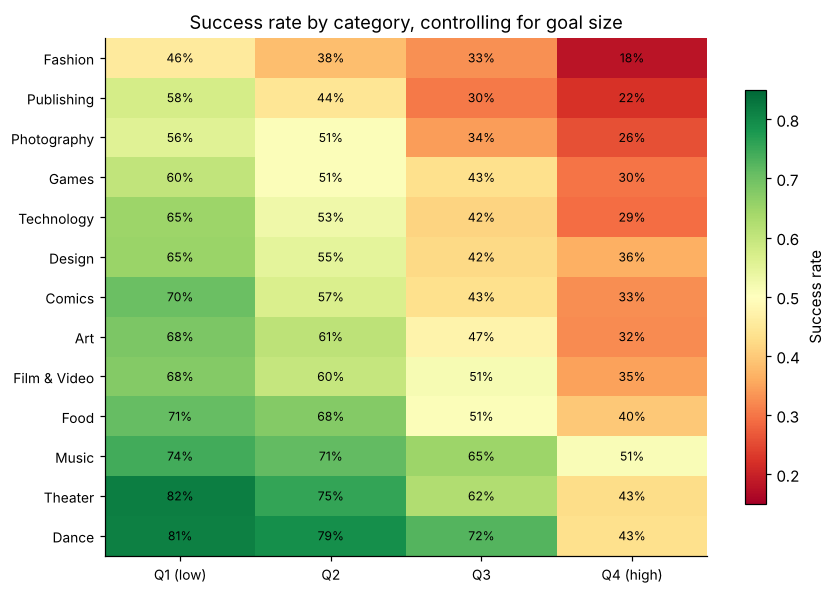

In [57]:
fig, ax = plt.subplots(figsize=(8, 5.5))
data = pivot.loc[pivot.mean(axis=1).sort_values().index]
im = ax.imshow(data.values, cmap="RdYlGn", vmin=0.15, vmax=0.85, aspect="auto")
ax.set_xticks(range(data.shape[1])); ax.set_xticklabels(data.columns, fontsize=9)
ax.set_yticks(range(data.shape[0])); ax.set_yticklabels(data.index, fontsize=9)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8)
ax.set_title("Success rate by category, controlling for goal size")
ax.grid(False)
plt.colorbar(im, ax=ax, label="Success rate", shrink=0.8)
plt.tight_layout()
plt.savefig(FIG / "category_by_goal_quartile.png", dpi=130, bbox_inches="tight")
plt.show()

Read the rows, not the columns. Within *every* goal quartile the ordering
of categories is broadly preserved — so there is a genuine category effect
on top of the goal effect. Both belong in the model, and neither explains
the other away.

In [58]:
sub_tbl = success_by(train, "subcategory", min_n=80)
print("Top 8 subcategories:")
print(sub_tbl.nlargest(8, "success_rate")[["n", "success_rate", "ci95"]].round(3).to_string())
print("\nBottom 8 subcategories:")
print(sub_tbl.nsmallest(8, "success_rate")[["n", "success_rate", "ci95"]].round(3).to_string())

Top 8 subcategories:
                    n  success_rate   ci95
subcategory                               
Dance             502         0.767  0.037
Indie Rock       1360         0.756  0.023
Country & Folk    756         0.749  0.031
Classical Music   319         0.727  0.049
Jazz              302         0.715  0.051
Theater          1776         0.706  0.021
Rock             1270         0.680  0.026
Public Art        368         0.663  0.048

Bottom 8 subcategories:
                   n  success_rate   ci95
subcategory                              
Open Software    163         0.288  0.070
Video Games      549         0.293  0.038
Children's Book  406         0.325  0.046
Fashion          752         0.335  0.034
Technology       235         0.349  0.061
Nonfiction       637         0.361  0.037
Fiction          703         0.363  0.036
Hip-Hop          333         0.381  0.052


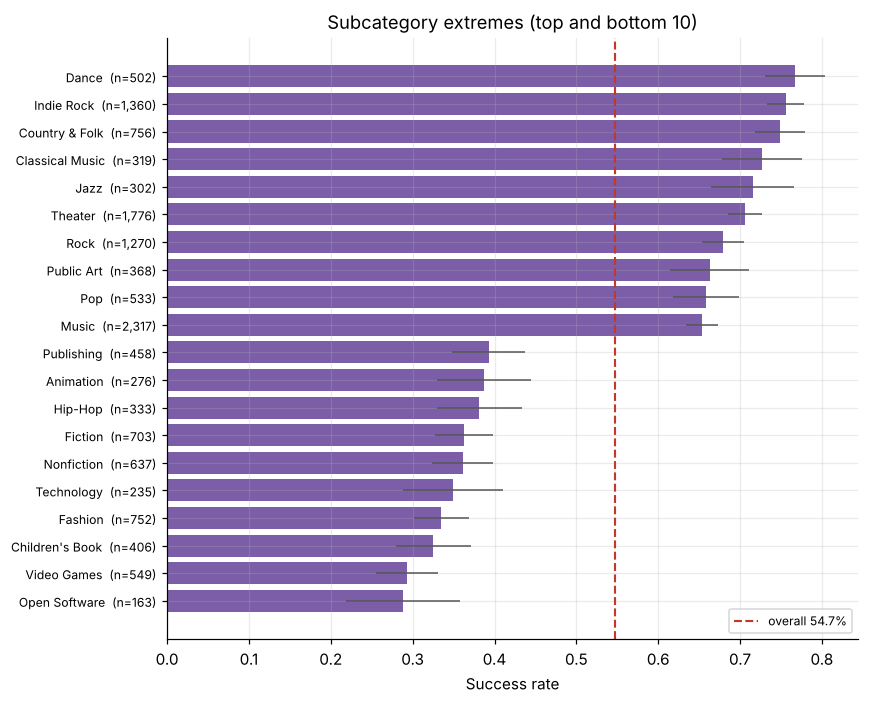

In [59]:
extremes = pd.concat([sub_tbl.nlargest(10, "success_rate"),
                      sub_tbl.nsmallest(10, "success_rate")])
barh_rates(extremes, "Subcategory extremes (top and bottom 10)",
           "success_by_subcategory.png", PLUM, figsize=(8, 6.5))

Subcategory spreads much wider than category — which is what makes it the
more valuable feature of the two despite the higher cardinality.

### 4.3 Duration — shorter is better

In [60]:
dur_tbl = success_by(train, "duration_bucket")
dur_tbl[["n", "success_rate", "ci95", "lift_vs_base"]].round(4)

,n,success_rate,ci95,lift_vs_base
duration_bucket,,,,
<=20d,2124,0.6780,0.0199,0.1306
21-30d,11079,0.5650,0.0092,0.0177
31-45d,8755,0.5860,0.0103,0.0386
46-60d,5327,0.4731,0.0134,-0.0743
>60d,3417,0.4258,0.0166,-0.1215


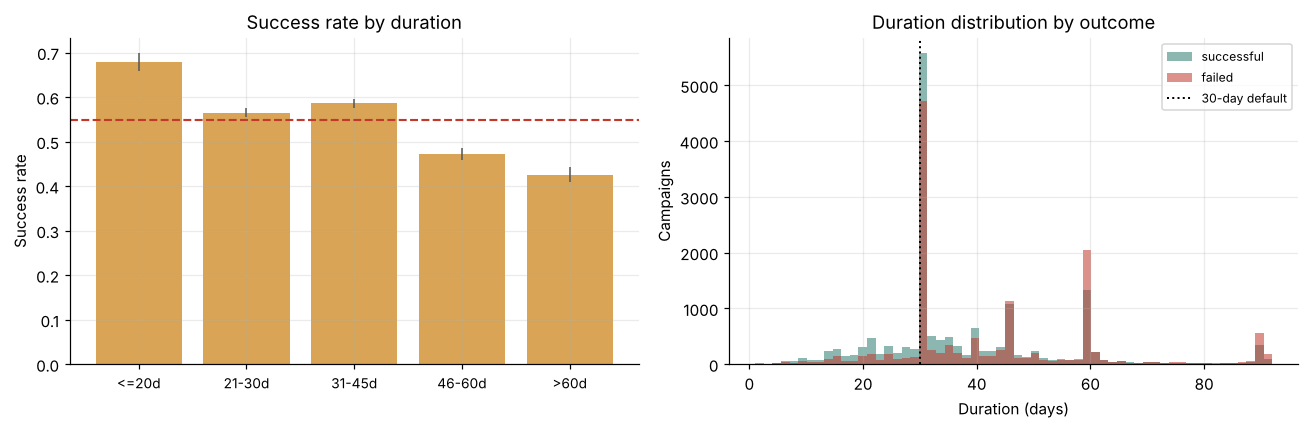

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
d = dur_tbl.reset_index()
axes[0].bar(range(len(d)), d["success_rate"], yerr=d["ci95"],
            color=SAND, error_kw={"ecolor": "#555", "lw": 1})
axes[0].axhline(BASE_RATE, color=CORAL, ls="--", lw=1.4)
axes[0].set_xticks(range(len(d)))
axes[0].set_xticklabels(d["duration_bucket"].astype(str), fontsize=9)
axes[0].set_ylabel("Success rate"); axes[0].set_title("Success rate by duration")

for label, sub, c in [("successful", train[train.success == 1], TEAL),
                      ("failed", train[train.success == 0], CORAL)]:
    axes[1].hist(sub["duration_days"], bins=60, alpha=0.55, label=label, color=c)
axes[1].axvline(30, color="black", ls=":", lw=1.3, label="30-day default")
axes[1].set_xlabel("Duration (days)"); axes[1].set_ylabel("Campaigns")
axes[1].set_title("Duration distribution by outcome"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "success_by_duration.png", dpi=130, bbox_inches="tight")
plt.show()

In [62]:
print(f"Median duration, successful: {train.loc[train.success == 1, 'duration_days'].median():.1f} days")
print(f"Median duration, failed:     {train.loc[train.success == 0, 'duration_days'].median():.1f} days")
print(f"\n30-day campaigns:     {train['is_30_day'].mean():.1%} of all campaigns")
print(f"  success rate:       {train.loc[train.is_30_day == 1, 'success'].mean():.1%}")
print(f"  vs non-30-day:      {train.loc[train.is_30_day == 0, 'success'].mean():.1%}")

Median duration, successful: 31.0 days
Median duration, failed:     35.0 days

30-day campaigns:     30.3% of all campaigns
  success rate:       53.0%
  vs non-30-day:      55.5%


Counter-intuitive but consistent: **longer campaigns do worse**. A long
window signals low confidence, and momentum matters more than time on
Kickstarter. This is directly actionable advice for a recommendation
engine, and it is known at launch.

**Correction (Milestone 4 re-check):** the 30-day platform default does *not*
outperform. The output above shows 30-day campaigns succeeding **less** often
than the rest (about 53% against 55.5%), and Task 11 in notebook 03 (§11.6) shows they
also do worse than 26–29 day campaigns within every goal quartile. Campaigns
left at the default are a dip, not a sweet spot.

### 4.4 Reward levels and tier structure

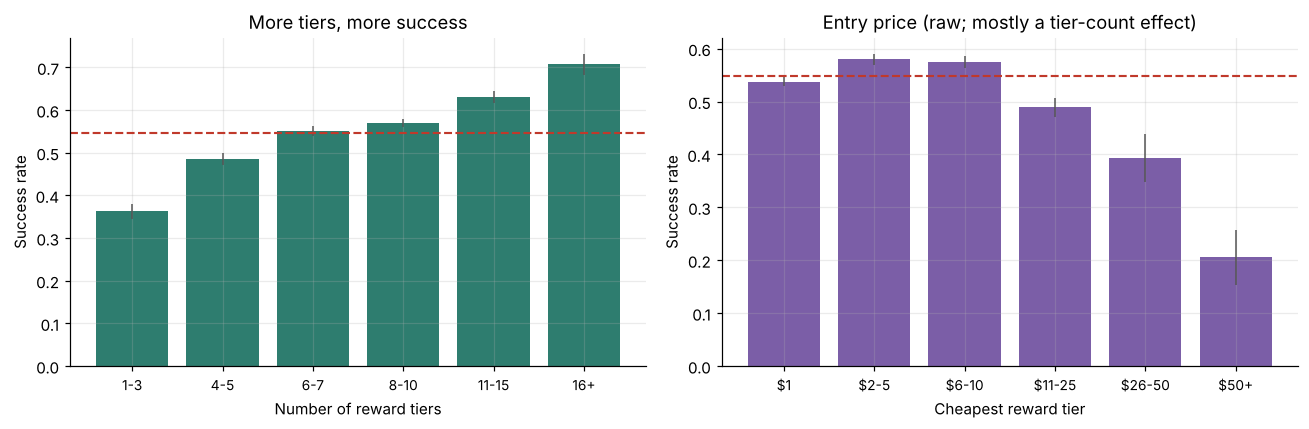

                n  success_rate
tier_bucket                    
1-3          2744         0.363
4-5          5148         0.485
6-7          7619         0.551
8-10         9194         0.570
11-15        4679         0.630
16+          1318         0.708

                     n  success_rate
min_tier_bucket                     
$1               11861         0.537
$2-5              8250         0.580
$6-10             6697         0.575
$11-25            3222         0.489
$26-50             443         0.393
$50+               229         0.205


In [63]:
train["tier_bucket"] = pd.cut(train["levels"], [0, 3, 5, 7, 10, 15, 100],
                              labels=["1-3", "4-5", "6-7", "8-10", "11-15", "16+"])
tier_tbl = success_by(train, "tier_bucket")

train["min_tier_bucket"] = pd.cut(train["min_tier"], [0, 1, 5, 10, 25, 50, 1e9],
                                  labels=["$1", "$2-5", "$6-10", "$11-25", "$26-50", "$50+"])
mintier_tbl = success_by(train, "min_tier_bucket")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, tbl, xlab, title, c in [
    (axes[0], tier_tbl, "Number of reward tiers", "More tiers, more success", TEAL),
    (axes[1], mintier_tbl, "Cheapest reward tier", "Entry price (raw; mostly a tier-count effect)", PLUM),
]:
    t = tbl.reset_index()
    ax.bar(range(len(t)), t["success_rate"], yerr=t["ci95"],
           color=c, error_kw={"ecolor": "#555", "lw": 1})
    ax.axhline(BASE_RATE, color=CORAL, ls="--", lw=1.4)
    ax.set_xticks(range(len(t))); ax.set_xticklabels(t.iloc[:, 0].astype(str), fontsize=9)
    ax.set_xlabel(xlab); ax.set_ylabel("Success rate"); ax.set_title(title)
plt.tight_layout()
plt.savefig(FIG / "success_by_reward_tiers.png", dpi=130, bbox_inches="tight")
plt.show()

print(tier_tbl[["n", "success_rate"]].round(3).to_string())
print()
print(mintier_tbl[["n", "success_rate"]].round(3).to_string())

**More tiers, more success** is real, and it is a launch-time decision the
creator fully controls — the most useful finding in this notebook from a
*recommendation* standpoint (Milestone 4).

**Correction (Milestone 4 re-check):** the entry-price pattern on the right
is mostly a *tier-count* effect. Campaigns with a high entry price also offer
far fewer tiers (a median of 3 against 8). Holding goal size and tier count
fixed, the raw gap of about −23 points shrinks to a few points (Task 11 in notebook 03,
§11.6), and adding a $10 tier to a campaign with a high entry price moves the
model's prediction by about 0.1 point. So the advice is *offer more tiers*,
not *add a $5 tier*.

### 4.5 Location

In [64]:
state_tbl = success_by(train, "state_raw", min_n=150)
print(f"States with >=150 campaigns: {len(state_tbl)}")
print("\nTop 8:"); print(state_tbl.nlargest(8, "success_rate")[["n", "success_rate", "ci95"]].round(3).to_string())
print("\nBottom 8:"); print(state_tbl.nsmallest(8, "success_rate")[["n", "success_rate", "ci95"]].round(3).to_string())

States with >=150 campaigns: 32

Top 8:
              n  success_rate   ci95
state_raw                           
NY         5310         0.648  0.013
MA          958         0.629  0.031
OR          941         0.614  0.031
IL         1373         0.610  0.026
MN          490         0.600  0.043
ME          199         0.593  0.068
WA         1013         0.584  0.030
DC          343         0.583  0.052

Bottom 8:
              n  success_rate   ci95
state_raw                           
FL         1123         0.375  0.028
NV          252         0.401  0.061
GA          769         0.430  0.035
NJ          440         0.441  0.046
AZ          448         0.449  0.046
IN          301         0.472  0.056
UT          307         0.476  0.056
NM          201         0.483  0.069


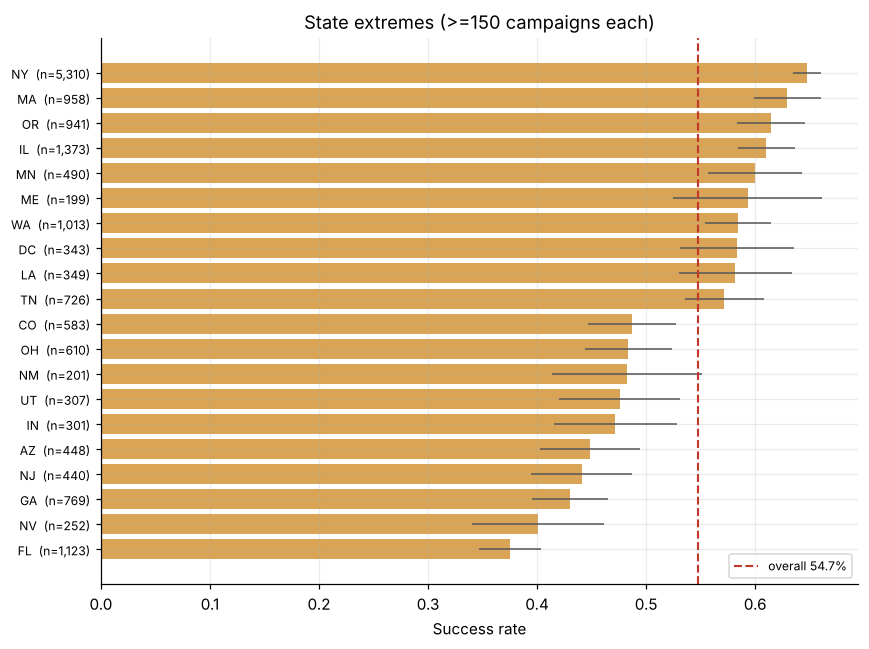

In [65]:
extremes = pd.concat([state_tbl.nlargest(10, "success_rate"),
                      state_tbl.nsmallest(10, "success_rate")])
barh_rates(extremes, "State extremes (>=150 campaigns each)",
           "success_by_state.png", SAND, figsize=(8, 6))

In [66]:
city_tbl = success_by(train, "city", min_n=120)
print(f"Cities with >=120 campaigns: {len(city_tbl)}")
print(city_tbl.sort_values("success_rate", ascending=False)[["n", "success_rate"]].round(3).to_string())

Cities with >=120 campaigns: 34
                    n  success_rate
city                               
Brooklyn         1217         0.723
Oakland           212         0.703
Austin            620         0.669
Portland          828         0.669
Philadelphia      452         0.657
Minneapolis       349         0.653
New York         2759         0.646
San Francisco     971         0.644
Chicago          1099         0.643
Boston            575         0.640
Seattle           675         0.631
Nashville         492         0.612
Lower East Side   120         0.608
Baltimore         211         0.602
Manhattan         223         0.601
New Orleans       230         0.600
Kansas City       135         0.593
Washington        347         0.585
Los Angeles      2867         0.555
Denver            277         0.549
Pittsburgh        211         0.545
Columbus          122         0.516
St Louis          141         0.496
Detroit           258         0.496
Salt Lake City    150         0.

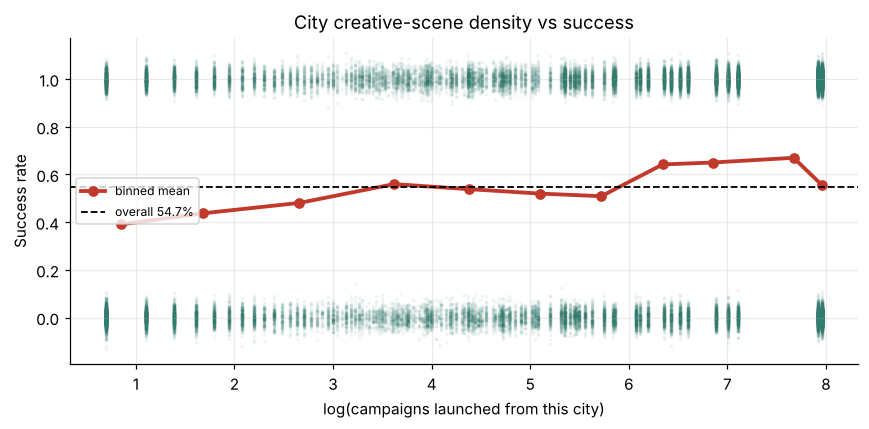

Spearman(log_city_project_count, success) = 0.1420


In [67]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(train["log_city_project_count"], train["success"] + np.random.normal(0, 0.03, len(train)),
           s=2, alpha=0.05, color=TEAL)
bins = pd.qcut(train["log_city_project_count"], 12, duplicates="drop")
b = train.groupby(bins, observed=True).agg(x=("log_city_project_count", "mean"),
                                           y=("success", "mean"))
ax.plot(b["x"], b["y"], color=CORAL, lw=2.5, marker="o", label="binned mean")
ax.axhline(BASE_RATE, color="black", ls="--", lw=1.2, label=f"overall {BASE_RATE:.1%}")
ax.set_xlabel("log(campaigns launched from this city)")
ax.set_ylabel("Success rate")
ax.set_title("City creative-scene density vs success")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "city_density_vs_success.png", dpi=130, bbox_inches="tight")
plt.show()

print(f"Spearman(log_city_project_count, success) = "
      f"{train['log_city_project_count'].corr(train['success'], method='spearman'):.4f}")

**Correction (Milestone 4 re-check):** location is **not** a modest signal.
The tables above show success running from about 65% (New York) to about 37%
(Florida) across states with 150+ campaigns — a spread of roughly 27 points
that survives controlling for goal size. By city size, the smallest quartile
succeeds about 43% of the time against about 62% for the largest. A rank
correlation of 0.14 made the city signal look weak, but the success rates show
it is not: city density is among the top handful of inputs the final model
relies on (Task 10 in notebook 02).

### 4.6 `updates` — the central methodological problem

Now the important part. `updates` is by far the strongest single predictor
in this dataset. It is also **not available at launch**.

In [68]:
train["update_bucket"] = pd.cut(train["updates"], [-1, 0, 1, 3, 6, 12, 1000],
                                labels=["0", "1", "2-3", "4-6", "7-12", "13+"])
upd_tbl = success_by(train, "update_bucket")
upd_tbl[["n", "success_rate", "ci95", "lift_vs_base"]].round(4)

,n,success_rate,ci95,lift_vs_base
update_bucket,,,,
0,10194,0.2036,0.0078,-0.3437
1,3784,0.4355,0.0158,-0.1118
2-3,5021,0.6411,0.0133,0.0937
4-6,4868,0.7837,0.0116,0.2363
7-12,4232,0.8651,0.0103,0.3177
13+,2603,0.9166,0.0106,0.3693


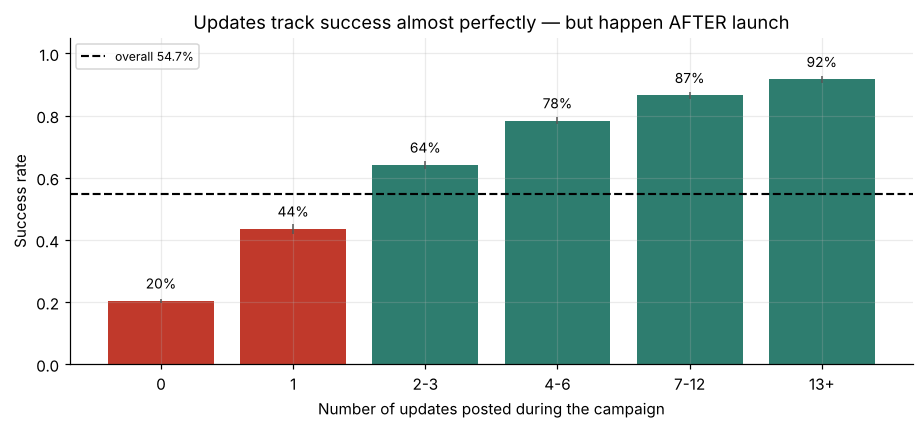

In [69]:
fig, ax = plt.subplots(figsize=(8.5, 4))
u = upd_tbl.reset_index()
bars = ax.bar(range(len(u)), u["success_rate"], yerr=u["ci95"],
              color=[CORAL if v < BASE_RATE else TEAL for v in u["success_rate"]],
              error_kw={"ecolor": "#555", "lw": 1})
ax.axhline(BASE_RATE, color="black", ls="--", lw=1.4, label=f"overall {BASE_RATE:.1%}")
ax.set_xticks(range(len(u))); ax.set_xticklabels(u["update_bucket"].astype(str))
ax.set_xlabel("Number of updates posted during the campaign")
ax.set_ylabel("Success rate")
ax.set_title("Updates track success almost perfectly — but happen AFTER launch")
ax.legend(fontsize=8)
for i, v in enumerate(u["success_rate"]):
    ax.text(i, v + 0.04, f"{v:.0%}", ha="center", fontsize=9)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(FIG / "updates_leakage.png", dpi=130, bbox_inches="tight")
plt.show()

From ~20% success at zero updates to ~92% at thirteen or more. No other
feature in the dataset comes close.

But consider what generates that number. A campaign that is visibly funding
well attracts a creator who keeps posting. A campaign that stalls goes
quiet. The causal arrow runs at least partly **backwards** — success causes
updates, not only the reverse. And by construction, none of it exists at
the moment a creator needs the prediction.

**Implication for Milestone 3.** `updates` cannot be used in a model that
predicts from launch-time information. It should be excluded from the
primary feature set before any model is trained, and the decision recorded
in the leakage register. The published benchmark for this dataset (80.2%
accuracy, F1 0.834) was produced with `updates` included, so our pre-launch
results will not be directly comparable to it — that comparison belongs in
Milestone 3, not here.

> **Later decision (October, Task 6 in Task 2).** The team went on to include `updates` in the final model's feature set, for accuracy. The September analysis below is kept as written; Task 6 records why the decision changed and what it costs.

### 4.7 Which launch-time features carry the most signal

Ranking features *before* any model is fitted, so the ranking reflects the
data rather than one algorithm's inductive bias.

Two measures, because the feature types need different treatment:

- **Numeric** — absolute Spearman correlation with the target. Rank-based,
  so it is unaffected by the heavy skew in `goal`.
- **Categorical** — the success-rate spread between the best and worst
  levels that have at least 100 campaigns, which is how much outcome
  variation the feature separates.

In [70]:
NUMERIC = ["log_goal", "duration_days", "levels", "n_tiers_parsed",
           "log_min_tier", "log_max_tier", "median_tier", "tier_spread",
           "min_tier_pct_of_goal", "log_goal_per_day", "log_goal_per_tier",
           "launch_year", "launch_month", "launch_dow", "name_length",
           "name_word_count", "name_upper_ratio", "log_city_project_count",
           "log_goal_vs_subcat_median"]
CATEGORICAL = ["category", "subcategory", "state_raw"]

rows = []
for col in NUMERIC:
    rho = train[col].corr(train["success"], method="spearman")
    rows.append({"feature": col, "kind": "numeric",
                 "signal": abs(rho), "detail": f"Spearman {rho:+.3f}"})

for col in CATEGORICAL:
    g = success_by(train, col, min_n=100)["success_rate"]
    rows.append({"feature": col, "kind": "categorical",
                 "signal": g.max() - g.min(),
                 "detail": f"{g.min():.0%} to {g.max():.0%} across "
                           f"{len(g)} levels"})

signal = pd.DataFrame(rows).sort_values("signal", ascending=False)
signal.head(15).round(3).to_string(index=False)

'                  feature        kind  signal                      detail\n              subcategory categorical   0.479 29% to 77% across 48 levels\n                 category categorical   0.432 34% to 77% across 13 levels\n                state_raw categorical   0.348 37% to 71% across 40 levels\n        log_goal_per_tier     numeric   0.343             Spearman -0.343\n                 log_goal     numeric   0.261             Spearman -0.261\nlog_goal_vs_subcat_median     numeric   0.219             Spearman -0.219\n         log_goal_per_day     numeric   0.216             Spearman -0.216\n     min_tier_pct_of_goal     numeric   0.180             Spearman +0.180\n                   levels     numeric   0.144             Spearman +0.144\n           n_tiers_parsed     numeric   0.144             Spearman +0.144\n   log_city_project_count     numeric   0.142             Spearman +0.142\n            duration_days     numeric   0.133             Spearman -0.133\n               launch_do

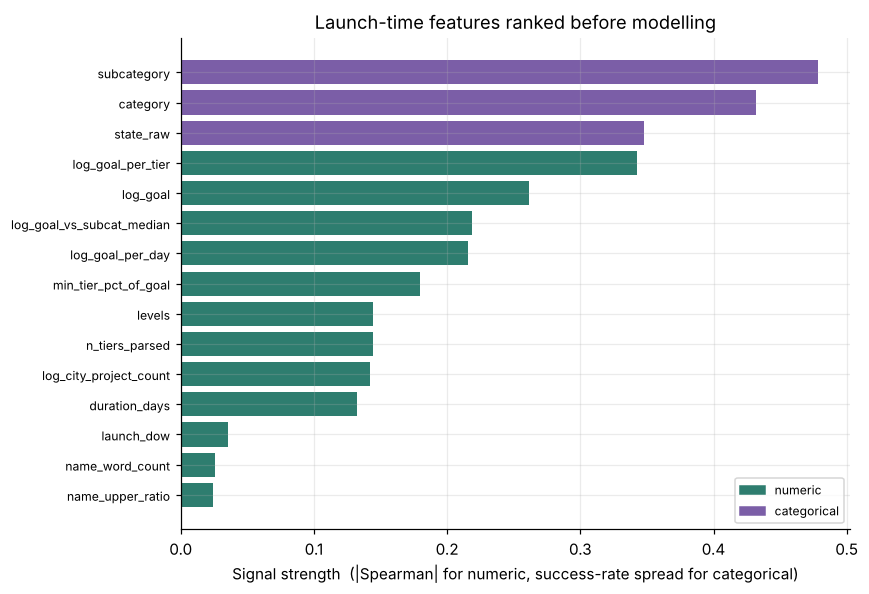

In [71]:
top = signal.head(15).iloc[::-1]
colors = [PLUM if k == "categorical" else TEAL for k in top["kind"]]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(range(len(top)), top["signal"], color=colors)
ax.set_yticks(range(len(top)))
ax.set_yticklabels(top["feature"], fontsize=8)
ax.set_xlabel("Signal strength  (|Spearman| for numeric, success-rate spread for categorical)")
ax.set_title("Launch-time features ranked before modelling")
handles = [plt.Rectangle((0, 0), 1, 1, color=TEAL),
           plt.Rectangle((0, 0), 1, 1, color=PLUM)]
ax.legend(handles, ["numeric", "categorical"], fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "launch_feature_signal.png", dpi=130, bbox_inches="tight")
plt.show()

The two measures are not on a common scale, so read within each colour
rather than across them. What the ranking says:

- **Goal dominates the numeric features**, in raw form and in every derived
  form (`log_goal_per_day`, `log_goal_per_tier`, `log_goal_vs_subcat_median`).
  Those four are all telling a version of the same story and will be
  collinear.
- **Subcategory separates outcomes more than category or state**, which is
  the case for carrying its higher cardinality into modelling.
- **Title features are weak** — length, word count and capitalisation barely
  move the needle. Worth keeping for now since they cost nothing, but they
  are the first candidates to drop in Milestone 3's feature selection.

### 4.8 Correlation structure

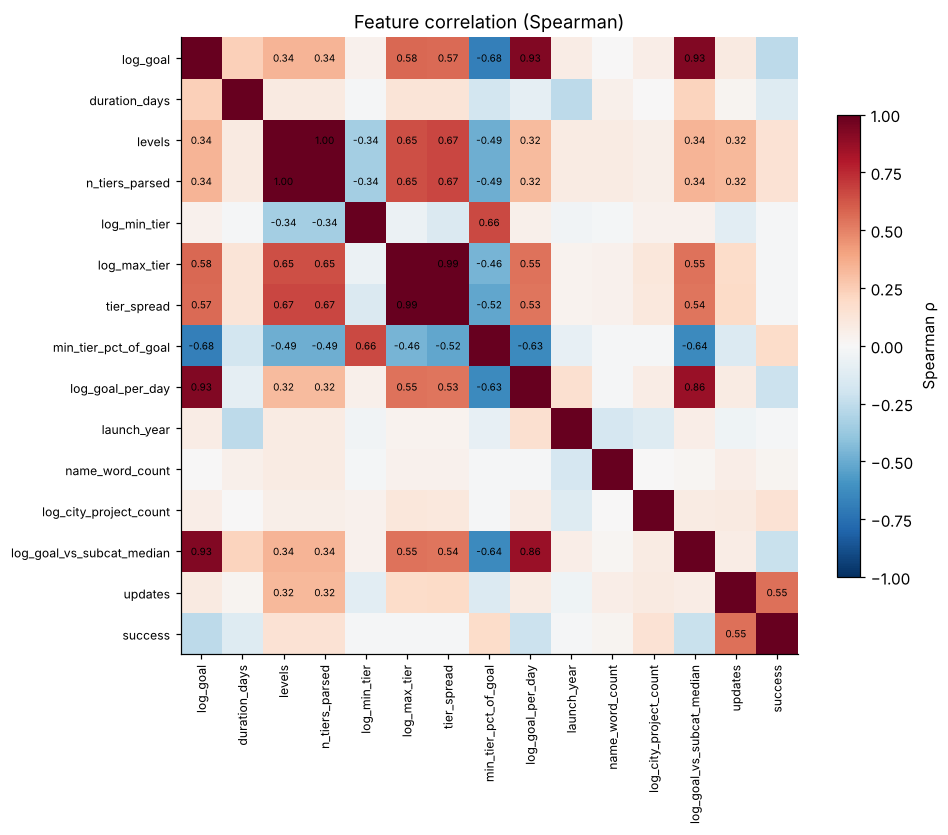

In [72]:
num = ["log_goal", "duration_days", "levels", "n_tiers_parsed", "log_min_tier",
       "log_max_tier", "tier_spread", "min_tier_pct_of_goal", "log_goal_per_day",
       "launch_year", "name_word_count", "log_city_project_count",
       "log_goal_vs_subcat_median", "updates", "success"]
corr = train[num].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=90, fontsize=8)
ax.set_yticks(range(len(num))); ax.set_yticklabels(num, fontsize=8)
for i in range(len(num)):
    for j in range(len(num)):
        v = corr.values[i, j]
        if abs(v) > 0.3 and i != j:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5)
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.75, label="Spearman ρ")
ax.set_title("Feature correlation (Spearman)")
plt.tight_layout()
plt.savefig(FIG / "correlation_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()

In [73]:
print("Correlation with success, ranked:")
print(corr["success"].drop("success").sort_values(ascending=False).round(4).to_string())

Correlation with success, ranked:
updates                      0.5527
min_tier_pct_of_goal         0.1799
n_tiers_parsed               0.1441
levels                       0.1441
log_city_project_count       0.1420
name_word_count              0.0255
tier_spread                 -0.0092
launch_year                 -0.0105
log_max_tier                -0.0113
log_min_tier                -0.0152
duration_days               -0.1326
log_goal_per_day            -0.2159
log_goal_vs_subcat_median   -0.2189
log_goal                    -0.2612


Two things to carry into Milestone 3:

- **Multicollinearity among the tier features.** `levels`,
  `n_tiers_parsed`, `log_max_tier` and `tier_spread` move together. Trees
  do not care; Logistic Regression coefficients will be unstable. Either
  regularise, or drop `n_tiers_parsed` since it duplicates `levels`.
- **`updates` dwarfs everything else** available in this file, which is the
  whole reason §4.6 exists.

### 4.9 Summary statistics table for the README

In [74]:
summary = pd.DataFrame({
    "successful": train[train.success == 1][["goal", "duration_days", "levels",
                                             "min_tier", "max_tier", "updates"]].median(),
    "failed": train[train.success == 0][["goal", "duration_days", "levels",
                                         "min_tier", "max_tier", "updates"]].median(),
})
summary["ratio"] = (summary["successful"] / summary["failed"]).round(2)
print("Median values by outcome (training split):")
print(summary.round(2).to_string())

Median values by outcome (training split):
               successful  failed  ratio
goal              3000.00  5000.0   0.60
duration_days       30.96    35.0   0.88
levels               8.00     7.0   1.14
min_tier             5.00     5.0   1.00
max_tier          1000.00  1000.0   1.00
updates              5.00     0.0    inf


In [75]:
summary.to_csv("../reports/m2_summary_by_outcome.csv")
signal.to_csv("../reports/m2_feature_signal_ranking.csv", index=False)
pd.concat([
    cat_tbl.assign(dimension="category"),
    dur_tbl.assign(dimension="duration"),
    upd_tbl.assign(dimension="updates"),
    tier_tbl.assign(dimension="reward_tiers"),
]).to_csv("../reports/m2_eda_success_rates.csv")
print("Wrote 3 CSVs to ../reports/ and "
      f"{len(list(FIG.glob('*.png')))} figures to ../reports/figures/")

Wrote 3 CSVs to ../reports/ and 43 figures to ../reports/figures/


### Findings — Tasks 4 & 5

#### Factors ranked by strength

| Rank | Factor | Effect | Available at launch? |
|---|---|---|---|
| 1 | **Updates** | 20% → 92% success from 0 to 13+ updates | ❌ **No** |
| 2 | **Goal** | Monotonic decline across all 10 deciles | ✅ Yes |
| 3 | **Subcategory** | Widest categorical spread | ✅ Yes |
| 4 | **Reward tiers** | More tiers help, within every goal size (the entry-price gap is mostly a tier-count effect) | ✅ Yes |
| 5 | **Duration** | Longer is *worse*; exactly-30-day (default) campaigns are a dip | ✅ Yes |
| 6 | **Category** | Real effect that survives controlling for goal | ✅ Yes |
| 7 | **Location** | Large — ~27 points between best and worst states; city size matters too | ✅ Yes |

*Rows 4, 5 and 7 were corrected in Milestone 4 after re-testing; the
original wording is recorded in Task 11 in notebook 03, §11.6.*

#### Recommendations for Milestone 3 (as written in September)

> **Later decision (October, Task 6 in Task 2).** The team went on to include `updates` in the final model's feature set, for accuracy. The September analysis below is kept as written; Task 6 records why the decision changed and what it costs.

1. **Exclude `updates` from the primary feature set.** It is the strongest
   signal in the data and also unavailable at launch, with causation running
   at least partly backwards. Record the decision in a leakage register
   before training anything. A second, clearly-labelled mid-campaign model
   could legitimately use it for triaging live campaigns.
2. **Exclude the outcome columns outright** — `pledged`, `backers`,
   `funded_percentage`, `comments`. `funded_percentage` mechanically
   determines the target.
3. **Use `log_goal`, not `goal`.** Five orders of magnitude of right skew.
4. **Expect collinearity** among the goal-derived features and among the
   reward-tier features. Trees will cope; Logistic Regression coefficients
   will not be stable without regularisation.
5. **Consider a chronological split** alongside the random one. `launch_date`
   was recovered in Milestone 1, and training on earlier campaigns to test on
   later ones matches the deployment scenario.
6. **Rank features with permutation importance or SHAP**, not Gini
   importance, which is biased toward continuous and high-cardinality
   features.

#### Confounds and caveats

1. **Category vs goal** — cheap categories ask for less and succeed more.
   Controlled for in §4.2 by comparing within goal quartiles; both effects
   are real.
2. **Random split, not chronological.** See recommendation 5.
3. **Platform drift.** The data spans 2009–2012 of a changing Kickstarter,
   including the June 2011 duration cap. `launch_year` partly absorbs this.
4. **The published 80.2% / F1 0.834 benchmark was produced with `updates`
   included.** Our pre-launch results will not be directly comparable, and
   the comparison belongs in Milestone 3.